# SHAP-Guided SMOTE Benchmark: Credit Card Fraud Detection (ULB)

**Research question.** Does using SHAP feature attributions *inside* the oversampler produce better synthetic
minority samples, and better minority-class classification, than conventional oversampling?

This notebook is one of four that run **the same experiment** on different datasets
(`01` Breast Cancer, `02` Credit Card Fraud, `03` Stroke, `04` NSL-KDD). All four are generated from one template
(`scripts/build_experiment_notebooks.py`) and import every algorithm from `src/`, so the only difference between
them is the dataset loaded in the first code cell. `05_cross_dataset_comparison.ipynb` compares the four.

| | Method | Type | How it creates minority samples |
|---|---|---|---|
| 0 | **No Sampling** | reference | none, trains on the imbalanced data |
| 1 | **Random Oversampling** | established | duplicates random minority rows |
| 2 | **SMOTE** | established (Chawla et al., 2002) | interpolates between a minority row and one of its k nearest minority neighbours (Euclidean) |
| 3 | **Borderline-SMOTE** | established (Han et al., 2005) | SMOTE, but only from minority rows near the class boundary (DANGER rows) |
| 4 | **SHAP-Filtered SMOTE** | **proposed** | SMOTE whose neighbours are searched only on the features that hold 90% of the SHAP importance |
| 5 | **SHAP-Weighted SMOTE** | **proposed** | SMOTE whose neighbour distance weights every feature by its SHAP importance: $d_W=\sqrt{\sum_j w_j (a_j-b_j)^2}$ |

**Stages:** 1 ingestion → 2 EDA → 3 leak-free preprocessing → 4 oversampling and synthetic-sample inspection →
5 repeated cross-validation → 6 hold-out test evaluation → 7 SHAP explainability comparison → 8 saved outputs,
summary and interpretation.

In [1]:
import sys, warnings
from pathlib import Path

# Locate the repository root (the folder that contains src/), wherever the notebook is run from
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "experiment").is_dir())
sys.path.insert(0, str(REPO_ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from src.experiment import config as C
from src.experiment import data as D, preprocessing as P, runner as R, inspection as I
from src.experiment import plots as PL, outputs as O, summary as S

%matplotlib inline
PL.set_style()
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

DATASET = "credit_card"   # <- the only line that differs between the four dataset notebooks
DIRS = O.results_dirs(DATASET)
PLOTS = DIRS["plots"]
display(C.settings_table())

,Value
Setting,
Random seed,42
Hold-out test size,"25% (stratified, untouched)"
Cross-validation,2 x 5-fold stratified on the development set
Oversampling target,1:1 minority:majority (sampling_strategy='auto')
k neighbours (all SMOTE variants),5
Borderline-SMOTE m neighbours,10
SHAP-Filtered cumulative threshold,0.9000
SHAP preliminary model,"Random Forest, 50 trees, depth 5 (training fol..."
SHAP rows explained,"all rows up to 20,000; above that all minority..."


## Stage 1: Data ingestion
The loader drops identifier and non-feature columns, exact duplicate rows and constant columns, and records any
one-off subsampling that fixes the imbalance ratio. None of these steps learns anything from the data. The
DataFrame index is the **original row number in the source file**, so every synthetic sample can later be traced
back to two real records.

In [2]:
df, spec = D.load_dataset(DATASET)
display(pd.Series({"Source": spec.source, "URL": spec.url, "License": spec.license, "File": spec.file,
                   "Target": spec.target_definition}, name=spec.title).to_frame())
display(Markdown("**Dataset-level steps applied by the loader:**\n" + "\n".join(f"- {n}" for n in spec.notes)))
print(f"Shape after loading: {df.shape[0]:,} rows x {df.shape[1] - 1} features + target")
display(df.head())

,Credit Card Fraud Detection (ULB)
Source,Worldline & ULB Machine Learning Group (Dal Po...
URL,https://www.kaggle.com/datasets/mlg-ulb/credit...
License,Open Database License (ODbL) 1.0
File,data/credit_card/creditcard.csv
Target,Class == 1 (fraud)


**Dataset-level steps applied by the loader:**
- `Time` dropped: seconds since the first transaction in the file, a row timestamp rather than a property of the transaction (same choice as the earlier credit-card notebook).
- Dropped 9,144 exact duplicate rows (features + target).

Shape after loading: 275,663 rows x 29 features + target


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,target
row_id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
0,-1.3598,-0.0728,2.5363,1.3782,-0.3383,0.4624,0.2396,0.0987,0.3638,0.0908,-0.5516,-0.6178,-0.9914,-0.3112,1.4682,-0.4704,0.2080,0.0258,0.4040,0.2514,-0.0183,0.2778,-0.1105,0.0669,0.1285,-0.1891,0.1336,-0.0211,149.6200,0
1,1.1919,0.2662,0.1665,0.4482,0.0600,-0.0824,-0.0788,0.0851,-0.2554,-0.1670,1.6127,1.0652,0.4891,-0.1438,0.6356,0.4639,-0.1148,-0.1834,-0.1458,-0.0691,-0.2258,-0.6387,0.1013,-0.3398,0.1672,0.1259,-0.0090,0.0147,2.6900,0
2,-1.3584,-1.3402,1.7732,0.3798,-0.5032,1.8005,0.7915,0.2477,-1.5147,0.2076,0.6245,0.0661,0.7173,-0.1659,2.3459,-2.8901,1.1100,-0.1214,-2.2619,0.5250,0.2480,0.7717,0.9094,-0.6893,-0.3276,-0.1391,-0.0554,-0.0598,378.6600,0
3,-0.9663,-0.1852,1.7930,-0.8633,-0.0103,1.2472,0.2376,0.3774,-1.3870,-0.0550,-0.2265,0.1782,0.5078,-0.2879,-0.6314,-1.0596,-0.6841,1.9658,-1.2326,-0.2080,-0.1083,0.0053,-0.1903,-1.1756,0.6474,-0.2219,0.0627,0.0615,123.5000,0
4,-1.1582,0.8777,1.5487,0.4030,-0.4072,0.0959,0.5929,-0.2705,0.8177,0.7531,-0.8228,0.5382,1.3459,-1.1197,0.1751,-0.4514,-0.2370,-0.0382,0.8035,0.4085,-0.0094,0.7983,-0.1375,0.1413,-0.2060,0.5023,0.2194,0.2152,69.9900,0


In [3]:
quality = D.quality_report(df, spec)
print(f"Numerical features ({len(spec.numeric_features)}): {', '.join(spec.numeric_features[:12])}"
      + (" ..." if len(spec.numeric_features) > 12 else ""))
print(f"Categorical features ({len(spec.categorical_features)}): {', '.join(spec.categorical_features) or 'none'}")
display(D.quality_summary(df, spec))
display(quality.sort_values("Missing", ascending=False).head(12))

Numerical features (29): V1, V2, V3, V4, V5, V6, V7, V8, V9, V10, V11, V12 ...
Categorical features (0): none


,Count,Handling
Check,,
Missing cells,0,Median / most-frequent imputation fitted on ea...
Infinite cells,0,Would be set to missing
Duplicate rows remaining,0,Exact duplicates already dropped at load time
Rows with |z| > 5 on any numeric feature,8371,Flagged only: in imbalanced problems extreme r...
Categorical features,0,One-hot encoded inside each training fold


,Type,dtype,Missing,Unique,Min,Max,Binary 0/1
Feature,,,,,,,
V1,numeric,float64,0,275663,-56.4075,2.4549,False
V2,numeric,float64,0,275663,-72.7157,22.0577,False
V3,numeric,float64,0,275663,-48.3256,9.3826,False
V4,numeric,float64,0,275663,-5.6832,16.8753,False
V5,numeric,float64,0,275663,-113.7433,34.8017,False
V6,numeric,float64,0,275663,-26.1605,73.3016,False
V7,numeric,float64,0,275663,-43.5572,120.5895,False
V8,numeric,float64,0,275663,-73.2167,20.0072,False
V9,numeric,float64,0,275663,-13.4341,15.5950,False


## Stage 2: Exploratory data analysis
EDA is descriptive only. The Kolmogorov-Smirnov ranking below only chooses which features to plot; it is never
used by any model or oversampler.

,Domain,Rows,Numeric features,Categorical features,Majority (0),Minority (1),Minority %,Imbalance ratio,Minority:majority
Dataset,,,,,,,,,
Credit Card Fraud Detection (ULB),Financial fraud,275663,29,0,275190,473,0.17%,581.8 : 1,1 : 581.8


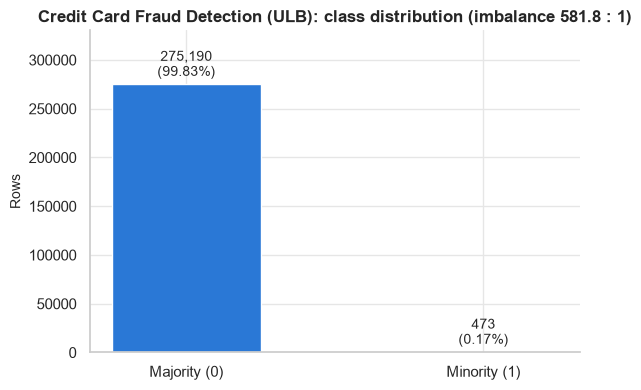

In [4]:
display(D.overview(df, spec))
PL.class_distribution(df, spec.title, PLOTS); plt.show()

,KS D (majority vs minority)
V14,0.8385
V10,0.7966
V12,0.7764
V4,0.7590
V11,0.7478
V17,0.7352
V3,0.6974
V16,0.6770
V7,0.6513
V2,0.6212


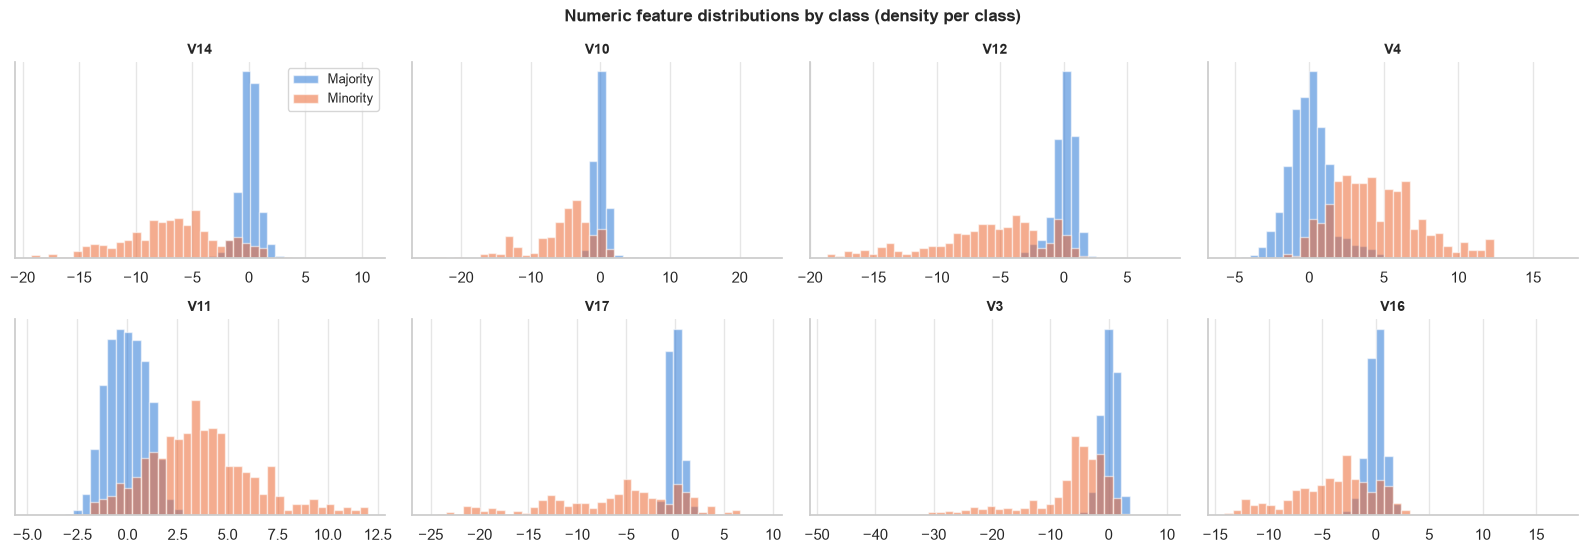

In [5]:
ks = D.ks_ranking(df, spec)
display(ks.head(10).to_frame("KS D (majority vs minority)"))
TOP_KS = list(ks.index[:8])
PL.feature_distributions(df, TOP_KS, PLOTS); plt.show()

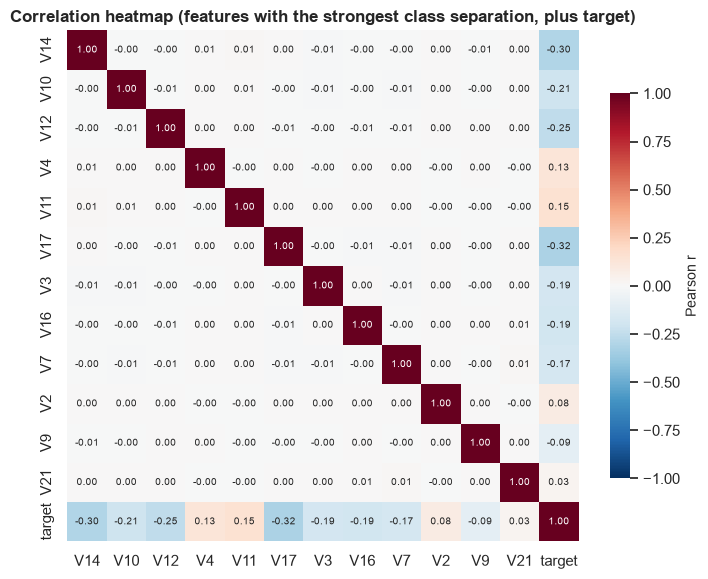

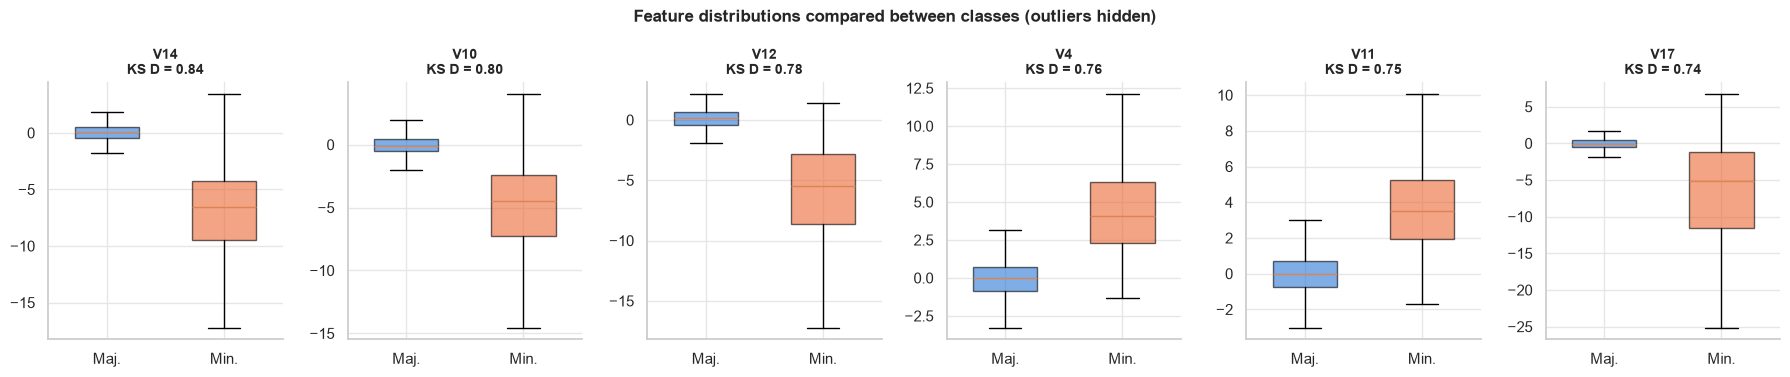

In [6]:
PL.correlation_heatmap(df, list(ks.index[:12]), PLOTS); plt.show()
PL.class_comparison(df, TOP_KS[:6], ks, PLOTS); plt.show()

## Stage 3: Leak-free preprocessing
```
full data --stratified 25%--> TEST (never resampled; used once, in Stage 6)
   └── DEVELOPMENT (75%) ── repeated stratified k-fold (Stage 5); in each fold, on the training part only:
                            impute + encode + scale  →  SHAP (inside the SHAP samplers)  →  oversample  →  fit model
```
Missing values: median (numeric) / most frequent (categorical) imputation. Categorical features are one-hot
encoded and numeric features are standardised. Every one of these steps is fitted on training rows only. The
table below shows the final fit on the whole development set: the scaler makes the development data exactly
mean 0, while the test set is only *close* to 0, because the test set was never used to fit anything.

In [7]:
dev_df, test_df = P.split_dev_test(df)
split = pd.DataFrame({"Rows": [len(dev_df), len(test_df)],
                      "Majority (0)": [int((dev_df.target == 0).sum()), int((test_df.target == 0).sum())],
                      "Minority (1)": [int(dev_df.target.sum()), int(test_df.target.sum())]},
                     index=["Development (75%)", "Hold-out test (25%)"])
split["Minority %"] = (split["Minority (1)"] / split["Rows"]).map("{:.2%}".format)
display(split)
assert not set(dev_df.index) & set(test_df.index), "development and test rows overlap"

pre = P.Preprocessor(spec).fit(dev_df)
print(f"Model space after encoding: {len(pre.feature_names_)} columns "
      f"({pre.n_numeric_} scaled numeric + {len(pre.feature_names_) - pre.n_numeric_} one-hot)")
display(pre.summary(dev_df, test_df).head(15))

,Rows,Majority (0),Minority (1),Minority %
Development (75%),206747,206392,355,0.17%
Hold-out test (25%),68916,68798,118,0.17%


Model space after encoding: 29 columns (29 scaled numeric + 0 one-hot)


,Kind,Missing (train),Imputation value (train median),Scaler mean (train),Scaler std (train),Train mean after,Test mean after
Feature,,,,,,,
V1,numeric,0,-0.0614,-0.0410,1.9586,-0.0000,0.0072
V2,numeric,0,0.0702,-0.0026,1.6704,0.0000,0.0005
V3,numeric,0,0.2025,0.0257,1.5161,0.0000,-0.0005
V4,numeric,0,-0.0367,-0.0022,1.4289,0.0000,-0.0060
V5,numeric,0,-0.0607,-0.0122,1.3809,0.0000,0.0044
V6,numeric,0,-0.2690,-0.0130,1.3114,-0.0000,-0.0035
V7,numeric,0,0.0450,0.0084,1.2501,-0.0000,0.0007
V8,numeric,0,0.0234,-0.0047,1.1895,0.0000,-0.0035
V9,numeric,0,-0.0657,-0.0138,1.1026,-0.0000,0.0052


## Stage 4: Oversampling and synthetic-sample inspection
The cell below fits **every sampler on the preprocessed development set** (the same chain is re-run inside every
CV fold in Stage 5) and fits the three downstream models on each resampled set. Test-set scores are only reported
in Stage 6.

All SMOTE-family methods share one generation engine (`src/oversampling/provenance.py`):
$x_{new} = x_a + \lambda (x_{nn} - x_a)$ with $\lambda \sim U(0,1)$, interpolated in the full, unweighted feature space.
They differ only in **which rows can be anchors** $x_a$ and **in which space the neighbour $x_{nn}$ is searched**.
They also share one random seed. For SMOTE, SHAP-Filtered SMOTE and SHAP-Weighted SMOTE (which all draw anchors
from every minority row), synthetic row *i* therefore has the same anchor, the same neighbour rank and the same
$\lambda$, so any difference between these three comes from neighbour selection alone. Borderline-SMOTE draws
from a smaller anchor pool, so its rows pair up differently. The engine records the parents, neighbour rank,
distance and $\lambda$ of every synthetic row.

No Sampling            sampled in    0.1 s, 3 models fitted and scored on the test set


Random Oversampling    sampled in    1.8 s, 3 models fitted and scored on the test set


SMOTE                  sampled in    5.9 s, 3 models fitted and scored on the test set


Borderline-SMOTE       sampled in   10.4 s, 3 models fitted and scored on the test set


SHAP-Filtered SMOTE    sampled in   30.9 s, 3 models fitted and scored on the test set


SHAP-Weighted SMOTE    sampled in   29.9 s, 3 models fitted and scored on the test set


,Anchor pool,Neighbour search space,Features in search,Search features (first 8),Synthetic rows
Method,,,,,
No Sampling,-,-,0,-,0
Random Oversampling,all minority rows,none (exact copies),0,-,206037
SMOTE,all minority rows,all features (Euclidean),29,"V1, V2, V3, V4, V5, V6, V7, V8 ...",206037
Borderline-SMOTE,DANGER rows only (40 of 355),all features (Euclidean),29,"V1, V2, V3, V4, V5, V6, V7, V8 ...",206037
SHAP-Filtered SMOTE,all minority rows,13 SHAP-selected features (Euclidean),13,"V1, V3, V4, V7, V9, V10, V11, V12 ...",206037
SHAP-Weighted SMOTE,all minority rows,"all features, column j scaled by sqrt(w_j)",29,"V1, V2, V3, V4, V5, V6, V7, V8 ...",206037


,real_majority,real_minority,synthetic_minority,final_majority,final_minority,sampling_seconds
method,,,,,,
No Sampling,206392,355,0,206392,355,0.0551
Random Oversampling,206392,355,206037,206392,206392,1.8222
SMOTE,206392,355,206037,206392,206392,5.9282
Borderline-SMOTE,206392,355,206037,206392,206392,10.4167
SHAP-Filtered SMOTE,206392,355,206037,206392,206392,30.9172
SHAP-Weighted SMOTE,206392,355,206037,206392,206392,29.9306


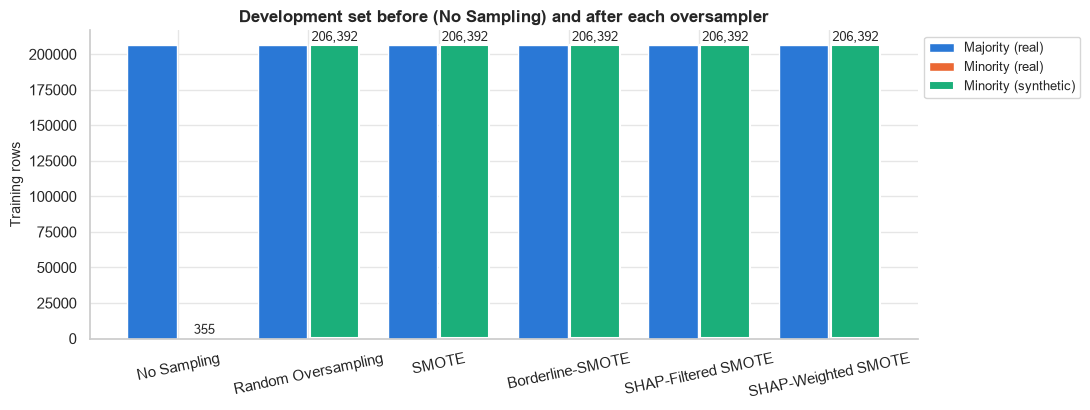

In [8]:
final = R.run_final(dev_df, test_df, spec)
display(I.search_space_description(final))
display(final.sampling)
PL.balanced_class_counts(final, PLOTS); plt.show()

### 4A. Neighbour identification
For each method: the k = 5 nearest minority neighbours of the first two minority seeds, the distance in the
method's search space, the plain Euclidean distance, the rank the same neighbour would have under plain SMOTE,
and the features that make up most of the search distance. For Borderline-SMOTE each seed is also labelled
SAFE / DANGER / NOISE from its 10 nearest neighbours in the whole training set; only DANGER rows can be anchors.

In [9]:
seed_ids = final.dev_row_ids[final.samplers["SMOTE"].minority_positions_[:2]]
for m in I.INTERPOLATING:
    t = I.neighbour_table(final, m, max_seeds=2)
    display(Markdown(f"**{m}**"))
    display(t.drop(columns="method"))
bl = final.samplers["Borderline-SMOTE"]
display(pd.Series({"SAFE": int(bl.safe_mask_.sum()), "DANGER (anchors)": int(bl.danger_mask_.sum()),
                   "NOISE": int(bl.noise_mask_.sum())}, name="Borderline-SMOTE seed status").to_frame())
display(I.neighbour_overlap_with_smote(final))

**SMOTE**

,seed_row_id,neighbour_rank,neighbour_row_id,search_distance,euclidean_distance,rank_under_plain_smote,top_features_in_search_distance
0,76929,1,249828,4.7462,4.7462,1,"V4 (14%), V15 (13%), V9 (12%)"
1,76929,2,251866,5.1450,5.1450,2,"V17 (27%), V10 (13%), V14 (11%)"
2,76929,3,214662,5.3018,5.3018,3,"V22 (19%), V14 (17%), V17 (11%)"
3,76929,4,163586,5.4777,5.4777,4,"V14 (47%), V25 (10%), V13 (8%)"
4,76929,5,189587,5.8874,5.8874,5,"V18 (14%), V17 (13%), V15 (12%)"
5,279863,1,281144,3.9178,3.9178,1,"V23 (20%), V25 (18%), V27 (14%)"
6,279863,2,163586,4.1821,4.1821,2,"V26 (20%), V1 (12%), Amount (9%)"
7,279863,3,108708,5.2036,5.2036,3,"V11 (19%), V26 (17%), V17 (16%)"
8,279863,4,57470,5.4681,5.4681,4,"V12 (14%), V14 (12%), V10 (12%)"
9,279863,5,230476,5.4891,5.4891,5,"V17 (20%), V19 (18%), V15 (10%)"


**Borderline-SMOTE**

,seed_row_id,seed_status,majority_in_10_nn,neighbour_rank,neighbour_row_id,search_distance,euclidean_distance,rank_under_plain_smote,top_features_in_search_distance
0,76929,SAFE,0,1,249828,4.7462,4.7462,1,"V4 (14%), V15 (13%), V9 (12%)"
1,76929,SAFE,0,2,251866,5.1450,5.1450,2,"V17 (27%), V10 (13%), V14 (11%)"
2,76929,SAFE,0,3,214662,5.3018,5.3018,3,"V22 (19%), V14 (17%), V17 (11%)"
3,76929,SAFE,0,4,163586,5.4777,5.4777,4,"V14 (47%), V25 (10%), V13 (8%)"
4,76929,SAFE,0,5,189587,5.8874,5.8874,5,"V18 (14%), V17 (13%), V15 (12%)"
5,279863,SAFE,1,1,281144,3.9178,3.9178,1,"V23 (20%), V25 (18%), V27 (14%)"
6,279863,SAFE,1,2,163586,4.1821,4.1821,2,"V26 (20%), V1 (12%), Amount (9%)"
7,279863,SAFE,1,3,108708,5.2036,5.2036,3,"V11 (19%), V26 (17%), V17 (16%)"
8,279863,SAFE,1,4,57470,5.4681,5.4681,4,"V12 (14%), V14 (12%), V10 (12%)"
9,279863,SAFE,1,5,230476,5.4891,5.4891,5,"V17 (20%), V19 (18%), V15 (10%)"


**SHAP-Filtered SMOTE**

,seed_row_id,neighbour_rank,neighbour_row_id,search_distance,euclidean_distance,rank_under_plain_smote,top_features_in_search_distance
0,76929,1,214662,3.6101,5.3018,3,"V14 (37%), V17 (23%), V11 (11%)"
1,76929,2,223572,3.8373,5.9336,6,"V9 (23%), V17 (17%), V16 (16%)"
2,76929,3,249828,3.9519,4.7462,1,"V4 (20%), V9 (18%), V16 (17%)"
3,76929,4,215132,4.0828,7.5265,31,"V14 (36%), V17 (15%), V1 (14%)"
4,76929,5,251866,4.4684,5.1450,2,"V17 (36%), V10 (18%), V14 (14%)"
5,279863,1,281144,2.1660,3.9178,1,"V27 (46%), V7 (24%), V1 (8%)"
6,279863,2,163586,2.7383,4.1821,2,"V1 (29%), V7 (17%), V9 (15%)"
7,279863,3,88307,3.5837,5.5502,8,"V14 (38%), V10 (20%), V7 (10%)"
8,279863,4,215132,3.6150,6.0914,19,"V11 (33%), V16 (20%), V17 (14%)"
9,279863,5,230476,3.7005,5.4891,5,"V17 (43%), V3 (12%), V7 (10%)"


**SHAP-Weighted SMOTE**

,seed_row_id,neighbour_rank,neighbour_row_id,search_distance,euclidean_distance,rank_under_plain_smote,top_features_in_search_distance
0,76929,1,249828,0.9733,4.7462,1,"V16 (24%), V11 (19%), V10 (14%)"
1,76929,2,223572,1.0520,5.9336,6,"V17 (28%), V16 (18%), V14 (11%)"
2,76929,3,223618,1.0880,6.2706,10,"V14 (22%), V4 (22%), V10 (18%)"
3,76929,4,214662,1.2808,5.3018,3,"V14 (56%), V17 (23%), V11 (6%)"
4,76929,5,263877,1.3765,6.1164,8,"V14 (29%), V17 (28%), V10 (10%)"
5,279863,1,281144,0.5218,3.9178,1,"V27 (37%), V7 (10%), V23 (7%)"
6,279863,2,163586,0.6993,4.1821,2,"V1 (22%), V10 (19%), V17 (12%)"
7,279863,3,93424,1.0600,5.5139,7,"V10 (44%), V17 (13%), V3 (12%)"
8,279863,4,212644,1.0741,7.5916,62,"V16 (28%), V27 (18%), V17 (14%)"
9,279863,5,230476,1.0967,5.4891,5,"V17 (62%), V16 (8%), V11 (5%)"


,Borderline-SMOTE seed status
SAFE,263
DANGER (anchors),40
NOISE,52


,mean_jaccard_with_SMOTE_neighbours,seeds_with_identical_neighbours
method,,
SMOTE,1.0000,1.0000
Borderline-SMOTE,1.0000,1.0000
SHAP-Filtered SMOTE,0.5564,0.1944
SHAP-Weighted SMOTE,0.5213,0.1493


### 4B. Synthetic sample generation
Below are the first synthetic records of each method, with their two parents (original row ids), $\lambda$ and
neighbour rank, followed by a feature-by-feature walk through synthetic row #0 of every interpolating method.
Because of the shared seed, row #0 of SMOTE, SHAP-Filtered and SHAP-Weighted SMOTE has the same anchor and the
same $\lambda$, so you can see how the choice of neighbour changes the result (Borderline-SMOTE's anchor comes
from its DANGER pool). A Random Oversampling record is an exact copy of parent 1.

In [10]:
for m in C.OVERSAMPLERS:
    rec = I.generation_records(final, m)
    display(Markdown(f"**{m}**: {len(rec):,} synthetic rows"))
    display(rec.head(4).iloc[:, :14])

**Random Oversampling**: 206,037 synthetic rows

,synthetic_id,method,parent_1_row_id,parent_2_row_id,neighbour_rank,lambda,search_distance,target,V1,V2,V3,V4,V5,V6
0,1-0,Random Oversampling,8615,NaN,NaN,NaN,NaN,1,-3.8912,7.0989,-11.4265,8.6076,-2.0657,-2.9853
1,1-1,Random Oversampling,68320,NaN,NaN,NaN,NaN,1,1.0366,0.4072,0.7577,3.1618,-0.5681,0.2022
2,1-2,Random Oversampling,9179,NaN,NaN,NaN,NaN,1,-2.8800,5.2254,-11.0633,6.6900,-5.7599,-2.2440
3,1-3,Random Oversampling,14338,NaN,NaN,NaN,NaN,1,1.1253,1.1301,-0.9630,2.6757,0.9901,-0.2433


**SMOTE**: 206,037 synthetic rows

,synthetic_id,method,parent_1_row_id,parent_2_row_id,neighbour_rank,lambda,search_distance,target,V1,V2,V3,V4,V5,V6
0,2-0,SMOTE,215984,"204,503.0000",4,0.4389,7.2665,1,-4.1144,-0.7529,-4.1006,1.8373,-1.7896,-0.2169
1,2-1,SMOTE,237107,"191,359.0000",5,0.6974,4.3820,1,1.1800,2.6883,-5.5740,5.3871,1.3269,-1.4438
2,2-2,SMOTE,88876,"123,201.0000",1,0.9756,1.1641,1,1.1416,1.2895,-1.4334,2.0584,0.9387,-0.9588
3,2-3,SMOTE,6882,"120,505.0000",4,0.7861,7.3291,1,-4.7559,3.0503,-4.6551,4.0985,-3.1739,-1.7236


**Borderline-SMOTE**: 206,037 synthetic rows

,synthetic_id,method,parent_1_row_id,parent_2_row_id,neighbour_rank,lambda,search_distance,target,V1,V2,V3,V4,V5,V6
0,3-0,Borderline-SMOTE,151807,"276,864.0000",4,0.4389,14.9545,1,-2.5964,4.2708,-4.0016,4.8014,-1.9685,1.4145
1,3-1,Borderline-SMOTE,6971,"226,814.0000",5,0.6974,13.4707,1,-2.7363,2.1312,-6.6703,3.9330,-5.8887,1.0195
2,3-2,Borderline-SMOTE,152019,"151,807.0000",1,0.9756,8.4281,1,-3.5559,5.3943,-3.7336,6.5579,-2.2215,2.4104
3,3-3,Borderline-SMOTE,149587,"40,085.0000",4,0.7861,6.3574,1,1.2701,1.2759,-1.9860,2.0800,1.0951,-0.9452


**SHAP-Filtered SMOTE**: 206,037 synthetic rows

,synthetic_id,method,parent_1_row_id,parent_2_row_id,neighbour_rank,lambda,search_distance,target,V1,V2,V3,V4,V5,V6
0,4-0,SHAP-Filtered SMOTE,215984,"77,348.0000",4,0.4389,4.0132,1,-3.2860,-0.4469,-3.8641,2.4241,-1.7292,-0.0708
1,4-1,SHAP-Filtered SMOTE,237107,"255,403.0000",5,0.6974,3.7672,1,1.1750,2.6981,-5.3338,5.4217,1.2206,-1.4278
2,4-2,SHAP-Filtered SMOTE,88876,"123,201.0000",1,0.9756,0.6153,1,1.1416,1.2895,-1.4334,2.0584,0.9387,-0.9588
3,4-3,SHAP-Filtered SMOTE,6882,"238,222.0000",4,0.7861,5.7188,1,-4.3526,1.4798,-3.7384,3.2393,-0.4607,-1.7859


**SHAP-Weighted SMOTE**: 206,037 synthetic rows

,synthetic_id,method,parent_1_row_id,parent_2_row_id,neighbour_rank,lambda,search_distance,target,V1,V2,V3,V4,V5,V6
0,5-0,SHAP-Weighted SMOTE,215984,"212,516.0000",4,0.4389,1.1028,1,-3.2979,-0.6728,-4.5920,1.9770,-1.1355,0.1218
1,5-1,SHAP-Weighted SMOTE,237107,"41,569.0000",5,0.6974,1.0943,1,-1.2994,1.3169,-7.5012,7.2566,2.3663,-2.9081
2,5-2,SHAP-Weighted SMOTE,88876,"123,201.0000",1,0.9756,0.2134,1,1.1416,1.2895,-1.4334,2.0584,0.9387,-0.9588
3,5-3,SHAP-Weighted SMOTE,6882,"154,694.0000",4,0.7861,1.5555,1,-3.2494,3.9548,-8.1756,4.4169,-3.2730,-1.6880


In [11]:
for m in I.INTERPOLATING:
    if final.samplers[m].n_synthetic_ == 0:
        continue
    ex = I.example_walkthrough(final, m, 0, max_features=8)
    display(Markdown(f"**{ex.attrs['header']}**"))
    display(ex)

**SMOTE: synthetic #0 = parent_1 (row 215984) + 0.4389 x (parent_2 (row 204503) - parent_1); parent_2 is neighbour rank 4 in the search space**

,parent_1,parent_2,gap (p2 - p1),lambda x gap,synthetic
feature,,,,,
V1,-4.8617,-3.1590,1.7028,0.7473,-4.1144
V2,-2.7227,1.7655,4.4881,1.9697,-0.7529
V3,-4.6562,-3.3902,1.2661,0.5557,-4.1006
V4,2.5020,0.9874,-1.5146,-0.6647,1.8373
V5,-2.0083,-1.5099,0.4984,0.2187,-1.7896
V6,0.6154,-1.2810,-1.8964,-0.8323,-0.2169
V7,-3.4857,-2.7196,0.7661,0.3362,-3.1494
V8,1.8789,0.7183,-1.1605,-0.5093,1.3695


**Borderline-SMOTE: synthetic #0 = parent_1 (row 151807) + 0.4389 x (parent_2 (row 276864) - parent_1); parent_2 is neighbour rank 4 in the search space**

,parent_1,parent_2,gap (p2 - p1),lambda x gap,synthetic
feature,,,,,
V1,-3.5522,-1.3744,2.1777,0.9558,-2.5964
V2,5.4265,2.7932,-2.6333,-1.1557,4.2708
V3,-3.7318,-4.3466,-0.6148,-0.2698,-4.0016
V4,6.6791,2.4007,-4.2783,-1.8777,4.8014
V5,-2.1875,-1.6884,0.4991,0.2190,-1.9685
V6,2.4339,0.1111,-2.3228,-1.0194,1.4145
V7,-8.7481,-0.9220,7.8261,3.4347,-5.3134
V8,-12.1083,-2.1499,9.9584,4.3705,-7.7378


**SHAP-Filtered SMOTE: synthetic #0 = parent_1 (row 215984) + 0.4389 x (parent_2 (row 77348) - parent_1); parent_2 is neighbour rank 4 in the search space**

,parent_1,parent_2,gap (p2 - p1),lambda x gap,synthetic,SHAP weight w_j
feature,,,,,,
V14,-4.3504,-6.1743,-1.8239,-0.8005,-5.1509,0.1888
V17,-8.0780,-6.5365,1.5415,0.6765,-7.4015,0.1259
V12,-4.1021,-4.6864,-0.5843,-0.2564,-4.3585,0.1244
V10,-5.1130,-4.8811,0.2318,0.1017,-5.0112,0.0997
V16,-5.0374,-4.8497,0.1878,0.0824,-4.9550,0.0855
V11,2.9456,2.2551,-0.6905,-0.3030,2.6426,0.0683
V1,-4.8617,-1.2712,3.5905,1.5758,-3.2860,0.0497
V27,1.2152,0.6328,-0.5824,-0.2556,0.9596,0.0471


**SHAP-Weighted SMOTE: synthetic #0 = parent_1 (row 215984) + 0.4389 x (parent_2 (row 212516) - parent_1); parent_2 is neighbour rank 4 in the search space**

,parent_1,parent_2,gap (p2 - p1),lambda x gap,synthetic,SHAP weight w_j
feature,,,,,,
V14,-4.3504,-3.8283,0.5222,0.2292,-4.1213,0.1888
V17,-8.0780,-7.5510,0.5270,0.2313,-7.8467,0.1259
V12,-4.1021,-5.4189,-1.3168,-0.5779,-4.6800,0.1244
V10,-5.1130,-4.5013,0.6117,0.2684,-4.8445,0.0997
V16,-5.0374,-6.3665,-1.3291,-0.5833,-5.6207,0.0855
V11,2.9456,2.0931,-0.8525,-0.3742,2.5715,0.0683
V1,-4.8617,-1.2984,3.5633,1.5639,-3.2979,0.0497
V27,1.2152,0.6431,-0.5721,-0.2511,0.9641,0.0471


### 4C. SHAP guidance
Both proposed methods first fit a preliminary Random Forest (50 trees, depth 5) **on the training data only**,
explain it with `shap.TreeExplainer`, and turn the mean absolute SHAP value of each feature (MASV) into a weight
$w_j = \text{MASV}_j / \sum_k \text{MASV}_k$.
* **SHAP-Filtered SMOTE** searches neighbours only on the top features whose cumulative weight reaches 90%.
* **SHAP-Weighted SMOTE** multiplies every column by $\sqrt{w_j}$ before the Euclidean search, so the distance becomes
  $d_W(a,b)=\sqrt{\sum_j w_j (a_j-b_j)^2}$: high-SHAP features decide who counts as a neighbour.

The rationale tables show, for the first synthetic rows, the neighbour's rank in SHAP space and under plain SMOTE,
which features made up the SHAP distance, and how similar the two parents' SHAP explanations are (cosine).

,rank,MASV,weight_w,cumulative_weight,sqrt_w_stretch_vs_uniform,kept_by_SHAP_Filtered
V14,1,0.0007,0.1888,0.1888,2.3396,True
V17,2,0.0005,0.1259,0.3147,1.9108,True
V12,3,0.0005,0.1244,0.4390,1.8990,True
V10,4,0.0004,0.0997,0.5387,1.7003,True
V16,5,0.0003,0.0855,0.6242,1.5748,True
V11,6,0.0003,0.0683,0.6926,1.4077,True
V1,7,0.0002,0.0497,0.7423,1.2008,True
V27,8,0.0002,0.0471,0.7893,1.1682,True
V4,9,0.0001,0.0375,0.8269,1.0433,True
V7,10,0.0001,0.0252,0.8520,0.8544,True


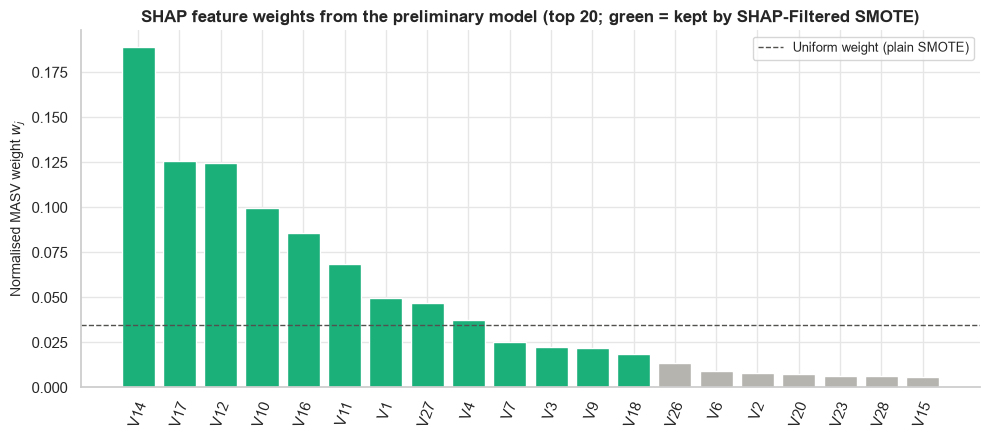

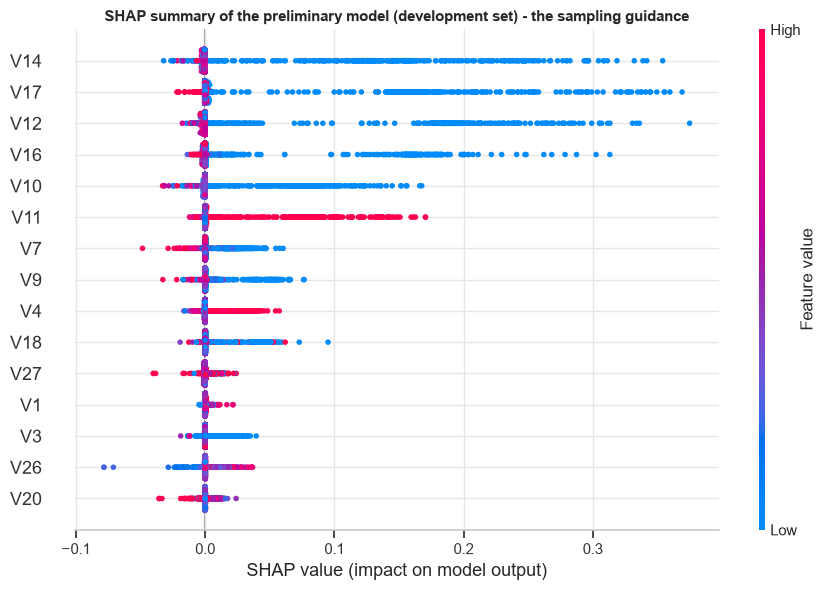

In [12]:
weights = I.shap_weight_table(final)
display(weights.head(15))
PL.masv_weights(weights, PLOTS); plt.show()
PL.shap_summary(final, PLOTS); plt.show()

In [13]:
for m in C.PROPOSED_METHODS:
    r = I.shap_rationale(final, m, n=8)
    display(Markdown(f"**{m}: neighbour-selection rationale (first 8 synthetic rows)**"))
    display(r)
    moved = (~r["would_plain_SMOTE_consider_it"]).mean()
    print(f"{moved:.0%} of these parent pairs would NOT be neighbours under plain SMOTE")
display(Markdown("**SHAP-Weighted SMOTE, synthetic row #0: parents' SHAP values on the highest-weight features**"))
display(I.parent_shap_detail(final, "SHAP-Weighted SMOTE", 0))

**SHAP-Filtered SMOTE: neighbour-selection rationale (first 8 synthetic rows)**

,parent_1_row_id,parent_2_row_id,lambda,rank_in_SHAP_space,rank_under_plain_SMOTE,parents_SHAP_cosine,distance_made_of,SHAP p1/p2 [V14],SHAP p1/p2 [V17],SHAP p1/p2 [V12],would_plain_SMOTE_consider_it
synthetic_index,,,,,,,,,,,
0,215984,77348,0.4389,4,10,0.9230,"V14 (23%), V1 (21%), V17 (21%)",+0.053 / +0.179,+0.295 / +0.256,+0.037 / +0.091,False
1,237107,255403,0.6974,5,4,0.9900,"V14 (32%), V17 (25%), V18 (13%)",+0.311 / +0.339,+0.000 / +0.003,+0.044 / +0.036,True
2,88876,123201,0.9756,1,1,0.9960,"V12 (70%), V14 (11%), V11 (7%)",+0.118 / +0.127,-0.001 / -0.002,-0.006 / -0.009,True
3,6882,238222,0.7861,4,3,0.9870,"V12 (33%), V14 (16%), V10 (14%)",+0.153 / +0.173,+0.166 / +0.181,+0.185 / +0.178,True
4,190368,189587,0.4504,1,1,0.9470,"V1 (45%), V10 (12%), V9 (10%)",+0.293 / +0.332,+0.023 / +0.021,+0.038 / +0.031,True
5,58422,101509,0.9268,2,9,0.9420,"V4 (29%), V16 (22%), V9 (22%)",-0.000 / -0.000,-0.000 / -0.000,-0.000 / -0.000,False
6,172787,214662,0.8228,4,4,0.9400,"V17 (26%), V27 (23%), V1 (15%)",+0.193 / +0.178,+0.217 / +0.172,+0.086 / +0.193,True
7,263877,214662,0.2272,3,6,0.9710,"V1 (23%), V10 (22%), V9 (19%)",+0.186 / +0.178,+0.191 / +0.172,+0.220 / +0.193,False


38% of these parent pairs would NOT be neighbours under plain SMOTE


**SHAP-Weighted SMOTE: neighbour-selection rationale (first 8 synthetic rows)**

,parent_1_row_id,parent_2_row_id,lambda,rank_in_SHAP_space,rank_under_plain_SMOTE,parents_SHAP_cosine,distance_made_of,SHAP p1/p2 [V14],SHAP p1/p2 [V17],SHAP p1/p2 [V12],would_plain_SMOTE_consider_it
synthetic_index,,,,,,,,,,,
0,215984,212516,0.4389,4,6,0.8790,"V12 (18%), V16 (16%), V1 (14%)",+0.053 / +0.015,+0.295 / +0.242,+0.037 / +0.219,False
1,237107,41569,0.6974,5,25,0.9350,"V16 (25%), V1 (14%), V23 (11%)",+0.311 / +0.319,+0.000 / +0.001,+0.044 / +0.166,False
2,88876,123201,0.9756,1,1,0.9960,"V12 (72%), V14 (17%), V11 (4%)",+0.118 / +0.127,-0.001 / -0.002,-0.006 / -0.009,True
3,6882,154694,0.7861,4,17,0.9920,"V27 (30%), V3 (17%), V10 (14%)",+0.153 / +0.146,+0.166 / +0.161,+0.185 / +0.193,False
4,190368,189587,0.4504,1,1,0.9470,"V1 (31%), V14 (24%), V10 (17%)",+0.293 / +0.332,+0.023 / +0.021,+0.038 / +0.031,True
5,58422,101509,0.9268,2,9,0.9420,"V16 (27%), V4 (15%), V12 (9%)",-0.000 / -0.000,-0.000 / -0.000,-0.000 / -0.000,False
6,172787,77348,0.8228,4,3,0.9560,"V14 (36%), V11 (20%), V17 (16%)",+0.193 / +0.179,+0.217 / +0.256,+0.086 / +0.091,True
7,263877,212644,0.2272,3,33,0.9890,"V14 (27%), V7 (14%), V27 (14%)",+0.186 / +0.159,+0.191 / +0.214,+0.220 / +0.221,False


62% of these parent pairs would NOT be neighbours under plain SMOTE


**SHAP-Weighted SMOTE, synthetic row #0: parents' SHAP values on the highest-weight features**

,SHAP weight w_j,in search space,share of search distance,SHAP parent 1,SHAP parent 2,value parent 1 (scaled),value parent 2 (scaled),synthetic (scaled)
feature,,,,,,,,
V14,0.1888,True,0.0464,0.0528,0.0151,-4.5561,-4.0091,-4.3161
V17,0.1259,True,0.0401,0.2948,0.2420,-9.5379,-8.9157,-9.2648
V12,0.1244,True,0.1780,0.0372,0.2186,-4.1059,-5.4254,-4.6850
V10,0.0997,True,0.0257,0.1022,0.0770,-4.6898,-4.1294,-4.4439
V16,0.0855,True,0.1598,0.2874,0.2475,-5.7086,-7.2161,-6.3702
V11,0.0683,True,0.0392,0.0217,0.0033,2.8939,2.0589,2.5274
V1,0.0497,True,0.1353,0.0029,0.0029,-2.4613,-0.6420,-1.6629
V27,0.0471,True,0.0781,0.0004,0.0032,3.0142,1.5937,2.3908
V4,0.0375,True,0.0216,0.0083,-0.0049,1.7525,0.9154,1.3851


### 4D. Quality of the synthetic samples
* **majority_share_in_5nn**: share of majority rows among the 5 nearest real development rows of each synthetic
  row. Higher means more synthetic points sit in majority territory, a proxy for label noise. The real
  minority rows give the reference value.
* **Fidelity** of synthetic vs real minority rows: marginal Wasserstein distance, KS-test pass rate and
  correlation-matrix similarity (does the synthetic data keep the real feature relationships?).
* **parents_SHAP_cosine_mean**: how similar the explanations of the two parents are.
* **detectability_auc_all / _numeric**: cross-validated ROC-AUC of a Random Forest trained to tell real minority rows
  from synthetic ones (0.5 = indistinguishable, 1 = trivially separable), on all model columns and on the numeric
  columns only. **fractional_onehot_cols_per_row** counts one-hot columns that interpolation left between 0 and 1
  (datasets with categorical features only). A detectable synthetic class can teach a model an artefact that never
  appears in real test rows.

,synthetic_rows,majority_share_in_5nn,synthetic_with_majority_nn1_%,mean_wasserstein_distance,max_wasserstein_distance,ks_test_pass_ratio,covariance_frobenius_dist,correlation_matrix_similarity,parents_SHAP_cosine_mean,distinct_parent_pairs,detectability_auc_all,detectability_auc_numeric
method,,,,,,,,,,,,
Real minority (reference),0,0.2507,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Random Oversampling,206037,0.1976,0.0000,0.0062,0.0143,1.0000,0.9852,1.0000,NaN,NaN,NaN,NaN
SMOTE,206037,0.1772,3.7200,0.1237,0.2494,0.9655,12.4534,0.9971,0.8965,"1,775.0000",0.5619,0.5619
Borderline-SMOTE,206037,0.3496,3.9600,1.1780,5.7337,0.0000,66.0212,0.9278,0.8593,200.0000,0.7844,0.7844
SHAP-Filtered SMOTE,206037,0.1756,4.3000,0.1196,0.2520,0.9655,12.0376,0.9970,0.9042,"1,775.0000",0.5782,0.5782
SHAP-Weighted SMOTE,206037,0.1867,4.0000,0.1199,0.2411,0.9655,10.7753,0.9969,0.9122,"1,775.0000",0.5755,0.5755


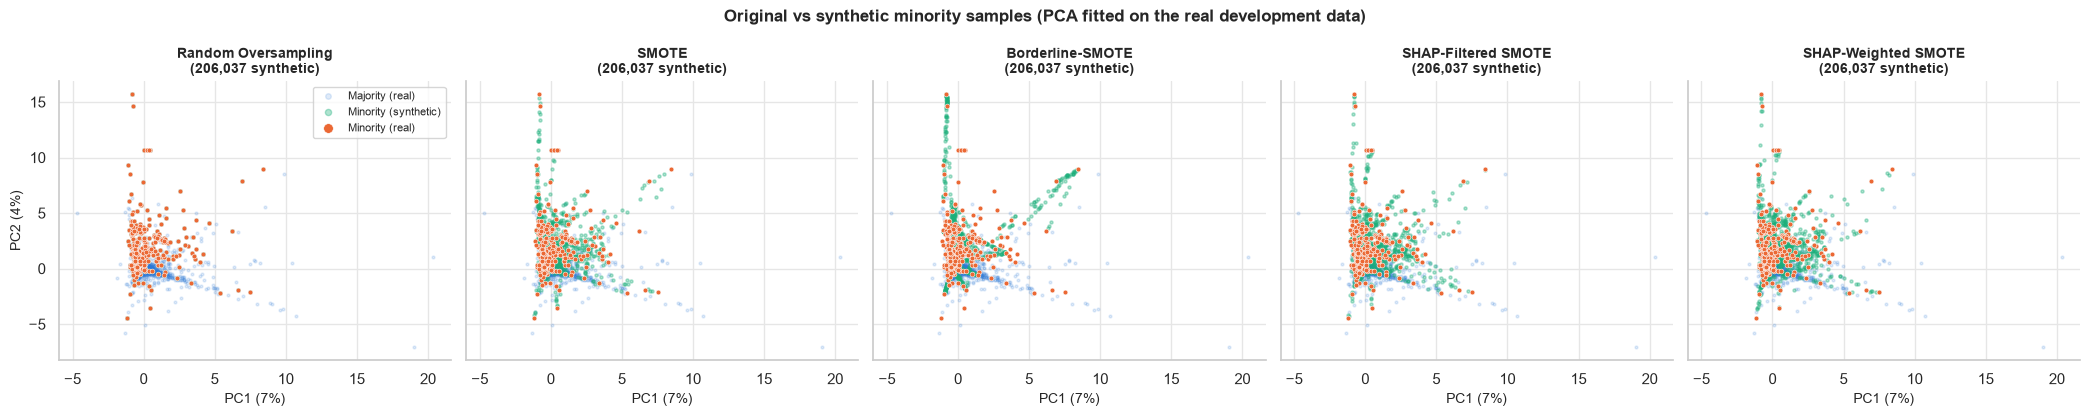

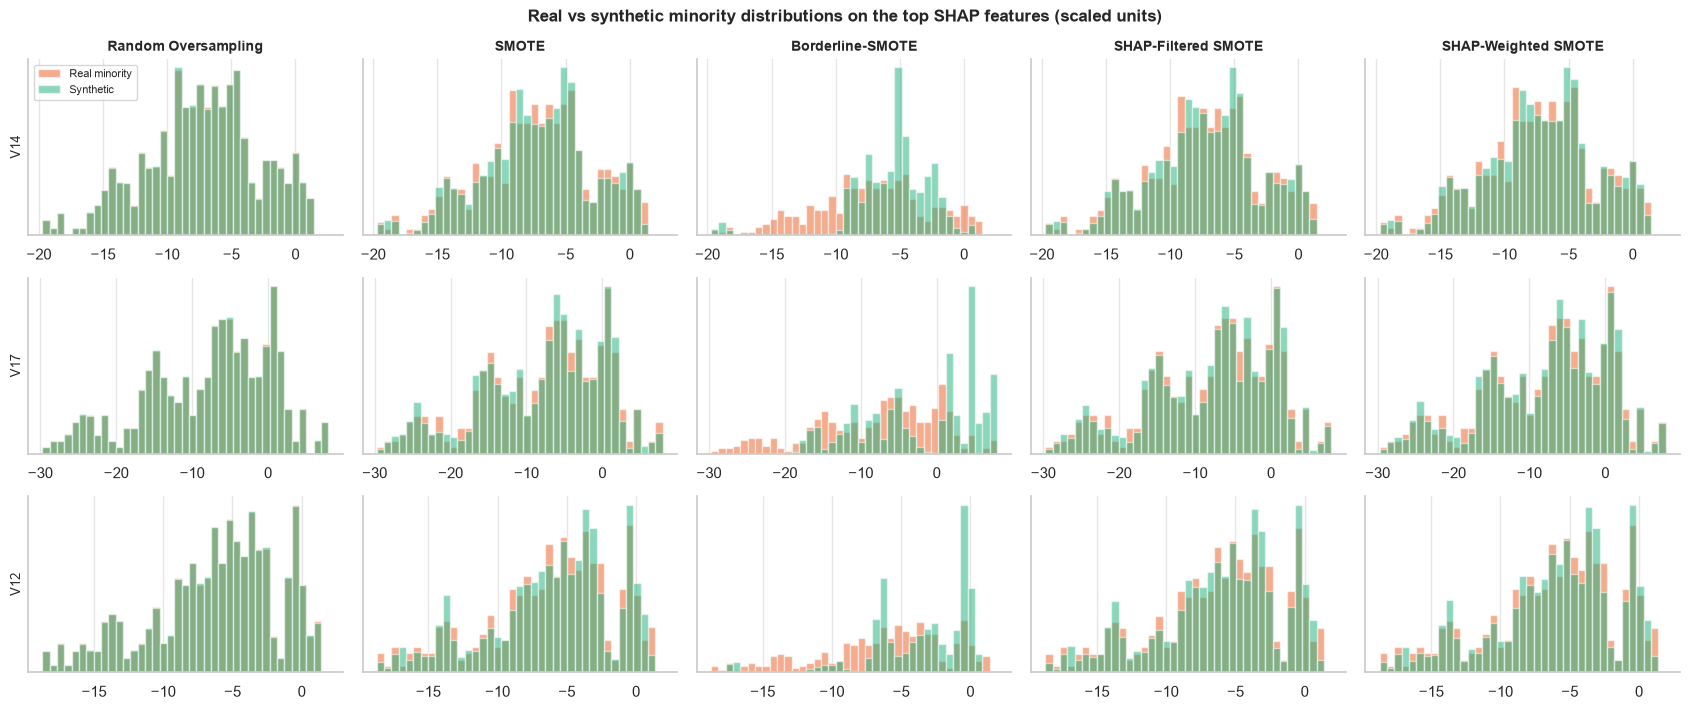

In [14]:
quality_tbl = I.synthetic_quality(final)
display(quality_tbl)
PL.pca_synthetic(final, PLOTS); plt.show()
PL.synthetic_feature_distributions(final, list(weights.index[:3]), PLOTS); plt.show()

In [15]:
files = O.save_sampling_artifacts(DIRS, final)
display(files)

,method,content,rows,file
0,Random Oversampling,synthetic samples,206037,results/credit_card/synthetic_samples/random_o...
1,SMOTE,synthetic samples,206037,results/credit_card/synthetic_samples/smote_sy...
2,SMOTE,neighbours,1775,results/credit_card/neighbour_analysis/smote_n...
3,Borderline-SMOTE,synthetic samples,206037,results/credit_card/synthetic_samples/borderli...
4,Borderline-SMOTE,neighbours,1775,results/credit_card/neighbour_analysis/borderl...
5,SHAP-Filtered SMOTE,synthetic samples,206037,results/credit_card/synthetic_samples/shap_fil...
6,SHAP-Filtered SMOTE,neighbours,1775,results/credit_card/neighbour_analysis/shap_fi...
7,SHAP-Weighted SMOTE,synthetic samples,206037,results/credit_card/synthetic_samples/shap_wei...
8,SHAP-Weighted SMOTE,neighbours,1775,results/credit_card/neighbour_analysis/shap_we...
9,SHAP-Filtered SMOTE,"SHAP rationale (first 2,000 rows)",2000,results/credit_card/neighbour_analysis/shap_fi...


## Stage 5: Repeated stratified cross-validation (leak-free)
For each of the 2 × 5 folds of the development set, the full chain (preprocessing → SHAP → oversampling → model) is
re-fitted on the training part with fresh objects, and scored on the untouched validation part. This gives a
mean ± standard deviation for every (method, model) pair, plus paired per-fold comparisons.

In [16]:
cv = R.run_cross_validation(dev_df, spec)
print(f"Cross-validation finished in {cv.elapsed_s / 60:.1f} min")

fold  1/10 done in 2373.2 s


fold  2/10 done in  360.9 s


fold  3/10 done in  522.0 s


fold  4/10 done in  370.6 s


fold  5/10 done in  479.5 s


fold  6/10 done in  623.0 s


fold  7/10 done in  336.3 s


fold  8/10 done in  348.8 s


fold  9/10 done in  496.3 s


fold 10/10 done in  396.6 s
Cross-validation finished in 105.1 min


In [17]:
for model in C.MODEL_ORDER:
    display(Markdown(f"**{model}: cross-validation, mean ± sd over {C.CV_SPLITS * C.CV_REPEATS} folds**"))
    display(S.cv_comparison_table(cv, model))

**Logistic Regression: cross-validation, mean ± sd over 10 folds**

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Specificity
Sampling Method,,,,,,,
No Sampling,0.999 ± 0.0,0.877 ± 0.034,0.62 ± 0.064,0.724 ± 0.041,0.974 ± 0.013,0.749 ± 0.054,1.0 ± 0.0
Random Oversampling,0.976 ± 0.002,0.061 ± 0.003,0.906 ± 0.038,0.114 ± 0.006,0.975 ± 0.009,0.725 ± 0.064,0.976 ± 0.002
SMOTE,0.973 ± 0.003,0.055 ± 0.004,0.906 ± 0.034,0.103 ± 0.008,0.975 ± 0.01,0.729 ± 0.067,0.973 ± 0.003
Borderline-SMOTE,0.991 ± 0.003,0.16 ± 0.055,0.837 ± 0.053,0.265 ± 0.075,0.942 ± 0.024,0.704 ± 0.07,0.992 ± 0.003
SHAP-Filtered SMOTE,0.973 ± 0.002,0.056 ± 0.003,0.911 ± 0.036,0.105 ± 0.006,0.974 ± 0.009,0.724 ± 0.067,0.973 ± 0.002
SHAP-Weighted SMOTE,0.973 ± 0.002,0.054 ± 0.003,0.908 ± 0.037,0.103 ± 0.006,0.974 ± 0.009,0.726 ± 0.068,0.973 ± 0.002


**Random Forest: cross-validation, mean ± sd over 10 folds**

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Specificity
Sampling Method,,,,,,,
No Sampling,0.999 ± 0.0,0.931 ± 0.025,0.752 ± 0.08,0.831 ± 0.056,0.97 ± 0.015,0.824 ± 0.067,1.0 ± 0.0
Random Oversampling,0.998 ± 0.0,0.52 ± 0.059,0.855 ± 0.058,0.643 ± 0.041,0.979 ± 0.012,0.762 ± 0.077,0.999 ± 0.0
SMOTE,0.997 ± 0.001,0.346 ± 0.066,0.858 ± 0.057,0.488 ± 0.057,0.981 ± 0.01,0.736 ± 0.077,0.997 ± 0.001
Borderline-SMOTE,0.997 ± 0.001,0.338 ± 0.077,0.846 ± 0.055,0.479 ± 0.078,0.976 ± 0.012,0.737 ± 0.07,0.997 ± 0.001
SHAP-Filtered SMOTE,0.997 ± 0.001,0.374 ± 0.058,0.858 ± 0.057,0.517 ± 0.05,0.982 ± 0.01,0.756 ± 0.064,0.997 ± 0.001
SHAP-Weighted SMOTE,0.997 ± 0.001,0.343 ± 0.078,0.859 ± 0.056,0.484 ± 0.067,0.981 ± 0.011,0.76 ± 0.056,0.997 ± 0.001


**XGBoost: cross-validation, mean ± sd over 10 folds**

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Specificity
Sampling Method,,,,,,,
No Sampling,1.0 ± 0.0,0.937 ± 0.036,0.8 ± 0.058,0.862 ± 0.04,0.979 ± 0.011,0.842 ± 0.054,1.0 ± 0.0
Random Oversampling,0.999 ± 0.0,0.603 ± 0.052,0.845 ± 0.057,0.701 ± 0.028,0.978 ± 0.011,0.826 ± 0.067,0.999 ± 0.0
SMOTE,0.995 ± 0.001,0.254 ± 0.031,0.866 ± 0.057,0.392 ± 0.034,0.976 ± 0.012,0.808 ± 0.073,0.996 ± 0.001
Borderline-SMOTE,0.999 ± 0.0,0.687 ± 0.062,0.828 ± 0.066,0.747 ± 0.032,0.976 ± 0.015,0.817 ± 0.054,0.999 ± 0.0
SHAP-Filtered SMOTE,0.996 ± 0.001,0.276 ± 0.033,0.863 ± 0.054,0.417 ± 0.035,0.977 ± 0.011,0.811 ± 0.07,0.996 ± 0.001
SHAP-Weighted SMOTE,0.996 ± 0.001,0.275 ± 0.024,0.863 ± 0.056,0.416 ± 0.026,0.976 ± 0.011,0.814 ± 0.061,0.996 ± 0.001


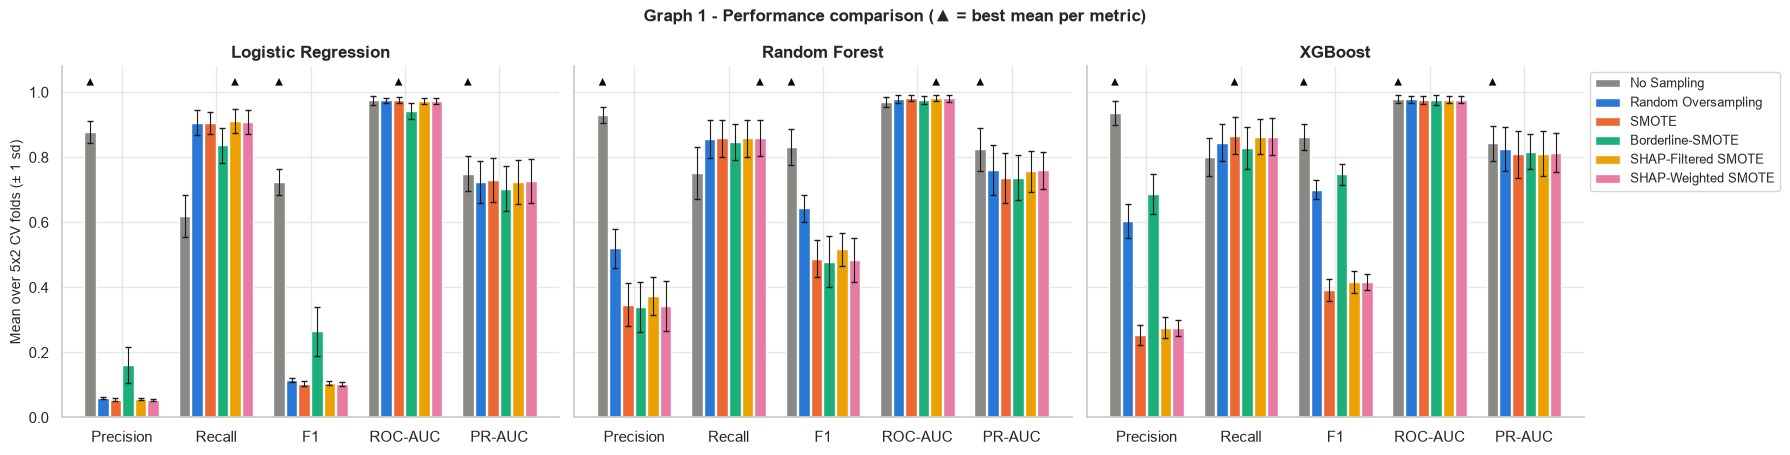

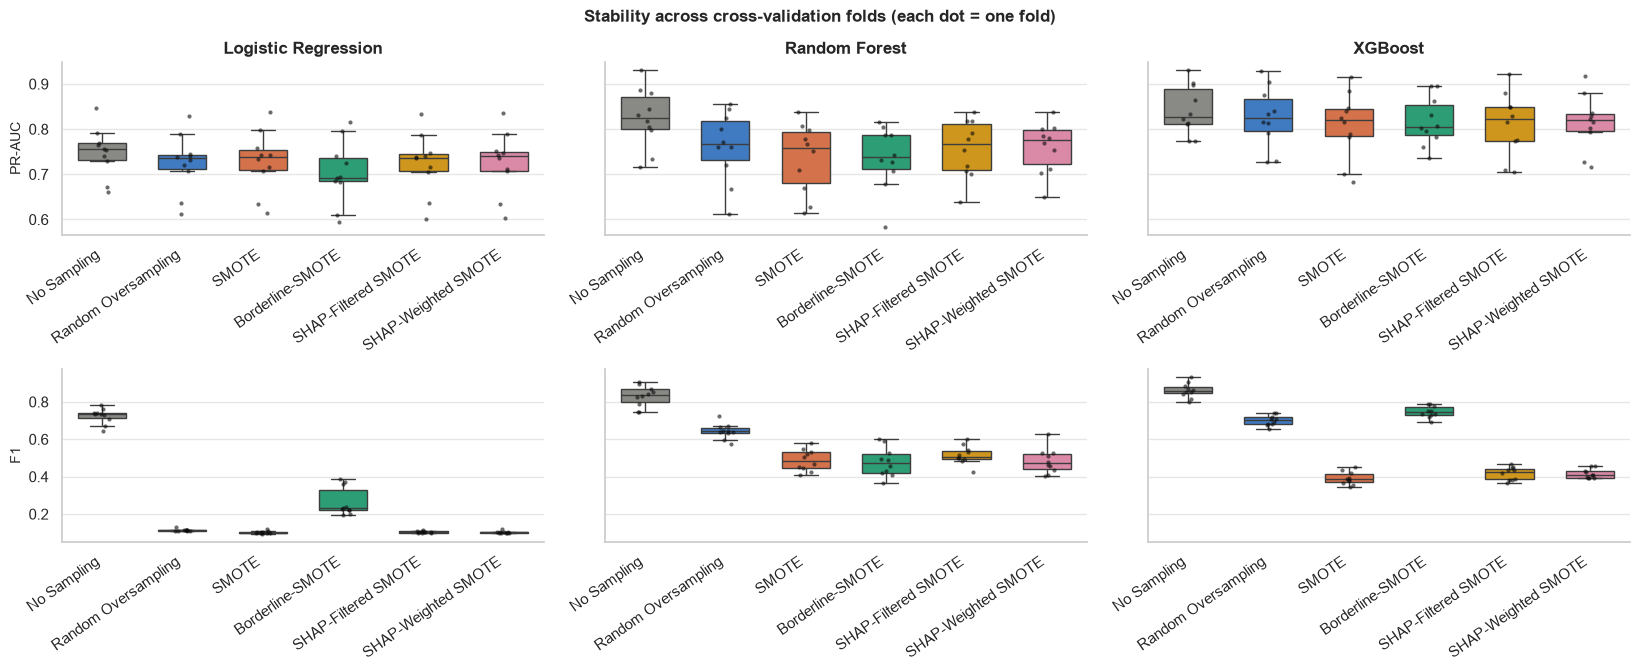

In [18]:
PL.performance_comparison(cv, PLOTS); plt.show()
PL.fold_distributions(cv, PLOTS); plt.show()

In [19]:
tests = R.paired_tests(cv)
display(Markdown("**Wilcoxon signed-rank tests vs SMOTE, paired by fold** (two-sided; p < 0.05 marked)"))
display(tests[tests.method.isin(C.PROPOSED_METHODS)].style.format({"mean_difference": "{:+.4f}", "p_value": "{:.3f}"})
        .apply(lambda r: ["font-weight: bold" if r.p_value < 0.05 else "" for _ in r], axis=1))

**Wilcoxon signed-rank tests vs SMOTE, paired by fold** (two-sided; p < 0.05 marked)

,model,method,vs,metric,mean_difference,folds_better,folds_worse,p_value
12,Logistic Regression,SHAP-Filtered SMOTE,SMOTE,PR-AUC,-0.0047,4,6,0.193
13,Logistic Regression,SHAP-Filtered SMOTE,SMOTE,F1,+0.0015,7,3,0.432
14,Logistic Regression,SHAP-Filtered SMOTE,SMOTE,Recall,+0.0056,4,0,0.125
15,Logistic Regression,SHAP-Filtered SMOTE,SMOTE,Precision,+0.0008,7,3,0.492
16,Logistic Regression,SHAP-Weighted SMOTE,SMOTE,PR-AUC,-0.0031,3,7,0.105
17,Logistic Regression,SHAP-Weighted SMOTE,SMOTE,F1,-0.0008,4,6,0.432
18,Logistic Regression,SHAP-Weighted SMOTE,SMOTE,Recall,+0.0028,3,1,0.625
19,Logistic Regression,SHAP-Weighted SMOTE,SMOTE,Precision,-0.0005,4,6,0.432
32,Random Forest,SHAP-Filtered SMOTE,SMOTE,PR-AUC,+0.0200,7,3,0.037
33,Random Forest,SHAP-Filtered SMOTE,SMOTE,F1,+0.0288,6,4,0.084


## Stage 6: Hold-out test evaluation
The models fitted in Stage 4 on the (resampled) development set are scored **once** on the untouched 25% test
set, at the 0.5 decision threshold. Test-set rankings rest on a single split and few minority cases, so read them
together with the cross-validation results in Stage 5.

In [20]:
for model in C.MODEL_ORDER:
    display(Markdown(f"**{model}: hold-out test set**"))
    display(S.comparison_table(final, model).style.format("{:.4f}").highlight_max(axis=0, props="font-weight: bold"))
cm = final.test_metrics.set_index(["model", "method"])[["tn", "fp", "fn", "tp", "brier", "ece"]]
display(Markdown("**Confusion-matrix counts and calibration (Brier score, ECE) on the test set**"))
display(cm)

**Logistic Regression: hold-out test set**

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Specificity
Sampling Method,,,,,,,
No Sampling,0.9990,0.8421,0.5424,0.6598,0.9644,0.7206,0.9998
Random Oversampling,0.9776,0.0648,0.8983,0.1208,0.9732,0.6650,0.9777
SMOTE,0.9747,0.0577,0.8983,0.1084,0.9693,0.6717,0.9748
Borderline-SMOTE,0.9900,0.1321,0.8644,0.2292,0.9509,0.6765,0.9903
SHAP-Filtered SMOTE,0.9744,0.0575,0.9068,0.1082,0.9719,0.6770,0.9745
SHAP-Weighted SMOTE,0.9747,0.0576,0.8983,0.1083,0.9717,0.6741,0.9748


**Random Forest: hold-out test set**

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Specificity
Sampling Method,,,,,,,
No Sampling,0.9993,0.9186,0.6695,0.7745,0.9591,0.7939,0.9999
Random Oversampling,0.9982,0.4778,0.8220,0.6044,0.9666,0.7372,0.9985
SMOTE,0.9972,0.3643,0.8305,0.5065,0.9761,0.7032,0.9975
Borderline-SMOTE,0.9960,0.2727,0.8136,0.4085,0.9753,0.6620,0.9963
SHAP-Filtered SMOTE,0.9974,0.3822,0.8390,0.5252,0.9732,0.7155,0.9977
SHAP-Weighted SMOTE,0.9971,0.3551,0.8305,0.4975,0.9703,0.6864,0.9974


**XGBoost: hold-out test set**

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Specificity
Sampling Method,,,,,,,
No Sampling,0.9994,0.9130,0.7119,0.8000,0.9740,0.8143,0.9999
Random Oversampling,0.9984,0.5161,0.8136,0.6316,0.9802,0.7982,0.9987
SMOTE,0.9952,0.2391,0.8390,0.3722,0.9673,0.7833,0.9954
Borderline-SMOTE,0.9989,0.6414,0.7881,0.7072,0.9791,0.7691,0.9992
SHAP-Filtered SMOTE,0.9947,0.2230,0.8390,0.3523,0.9703,0.7728,0.9950
SHAP-Weighted SMOTE,0.9950,0.2306,0.8305,0.3610,0.9656,0.7824,0.9952


**Confusion-matrix counts and calibration (Brier score, ECE) on the test set**

,,tn,fp,fn,tp,brier,ece
model,method,,,,,,
Logistic Regression,No Sampling,68786,12,54,64,0.0008,0.0005
Random Forest,No Sampling,68791,7,39,79,0.0005,0.0003
XGBoost,No Sampling,68790,8,34,84,0.0005,0.0003
Logistic Regression,Random Oversampling,67267,1531,12,106,0.0226,0.0763
Random Forest,Random Oversampling,68692,106,21,97,0.0085,0.0679
XGBoost,Random Oversampling,68708,90,22,96,0.0017,0.0090
Logistic Regression,SMOTE,67067,1731,12,106,0.0248,0.0781
Random Forest,SMOTE,68627,171,20,98,0.0127,0.0855
XGBoost,SMOTE,68483,315,19,99,0.0053,0.0250


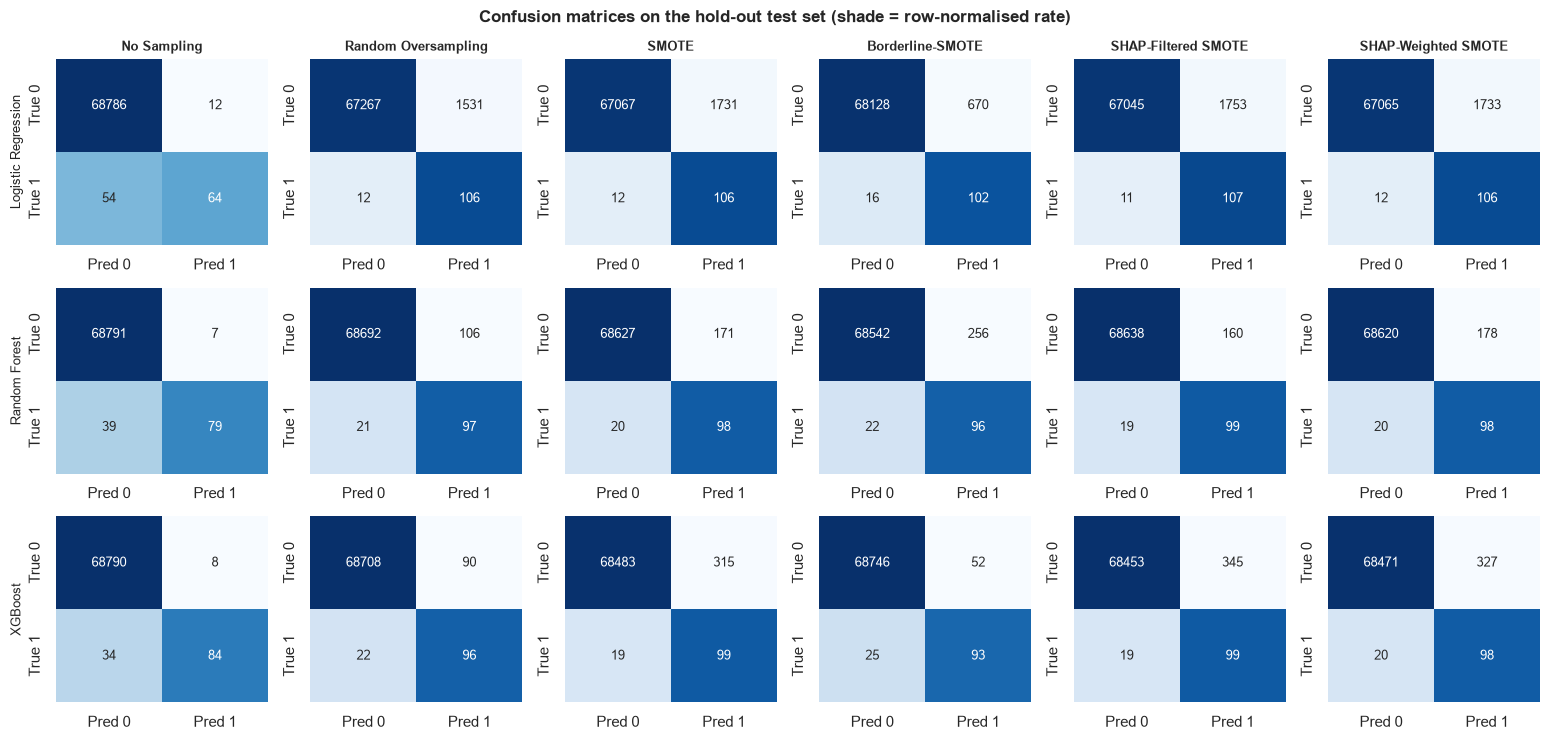

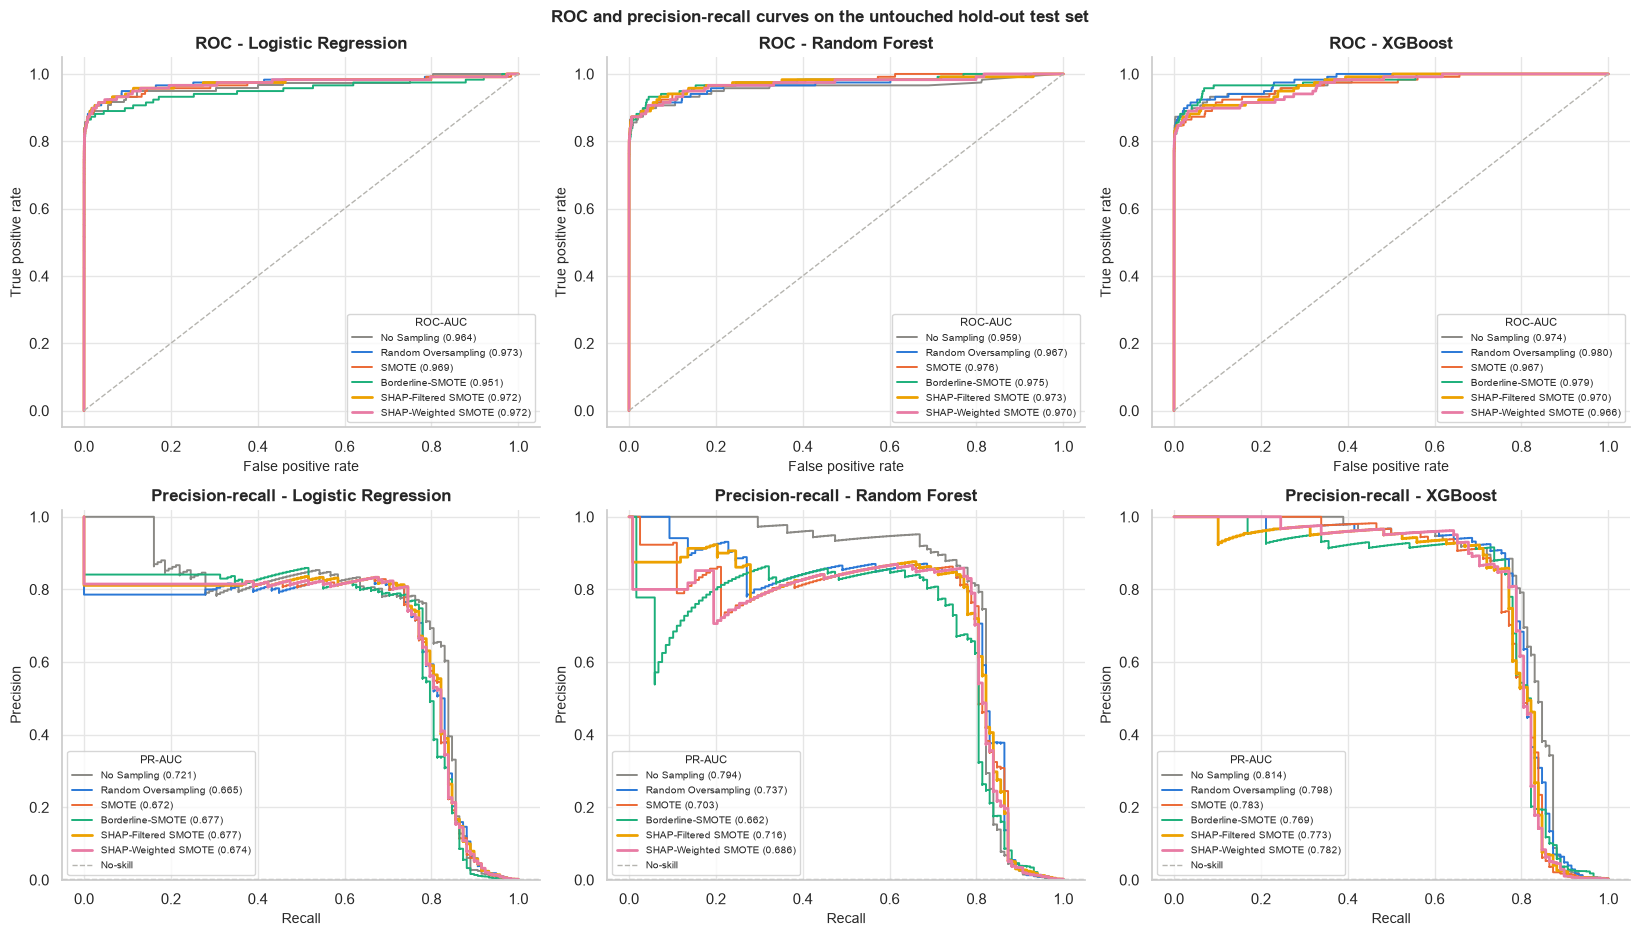

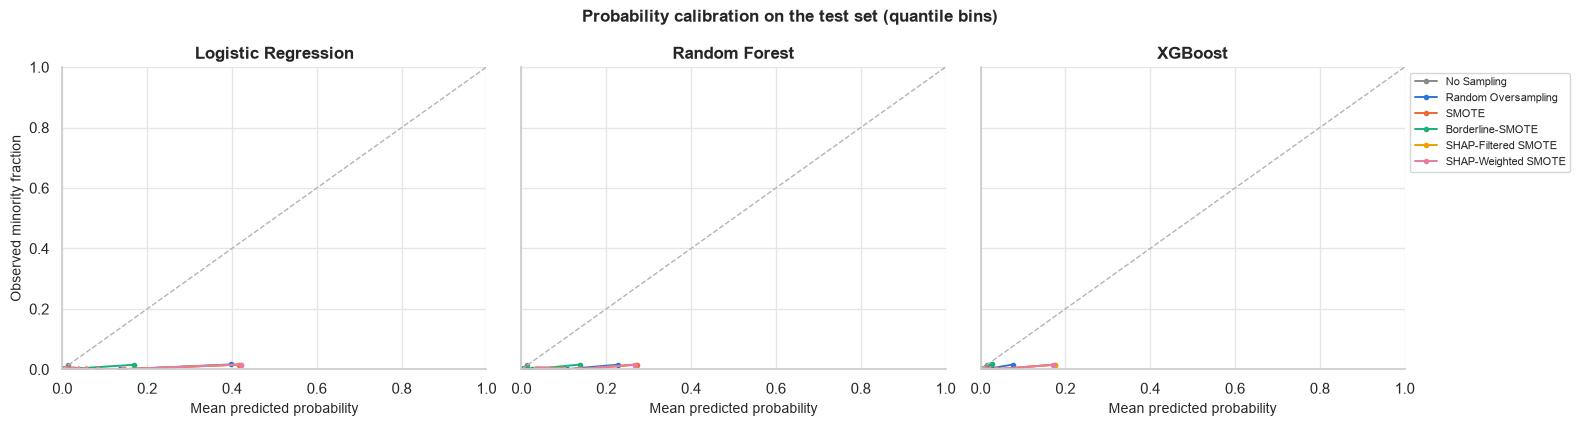

In [21]:
PL.confusion_matrices(final, PLOTS); plt.show()
PL.roc_pr_curves(final, PLOTS); plt.show()
PL.calibration_curves(final, PLOTS); plt.show()

## Stage 7: SHAP explainability comparison
Do the final models rely on different features depending on how their training data was balanced? Each final
model is explained on the same test rows (all minority rows up to 250, plus majority rows up to 500 in total).
Logistic Regression uses `LinearExplainer` with a training background; the tree models use `TreeExplainer`.
Across CV folds, the stability of each model's SHAP feature ranking is measured with Kendall τ.

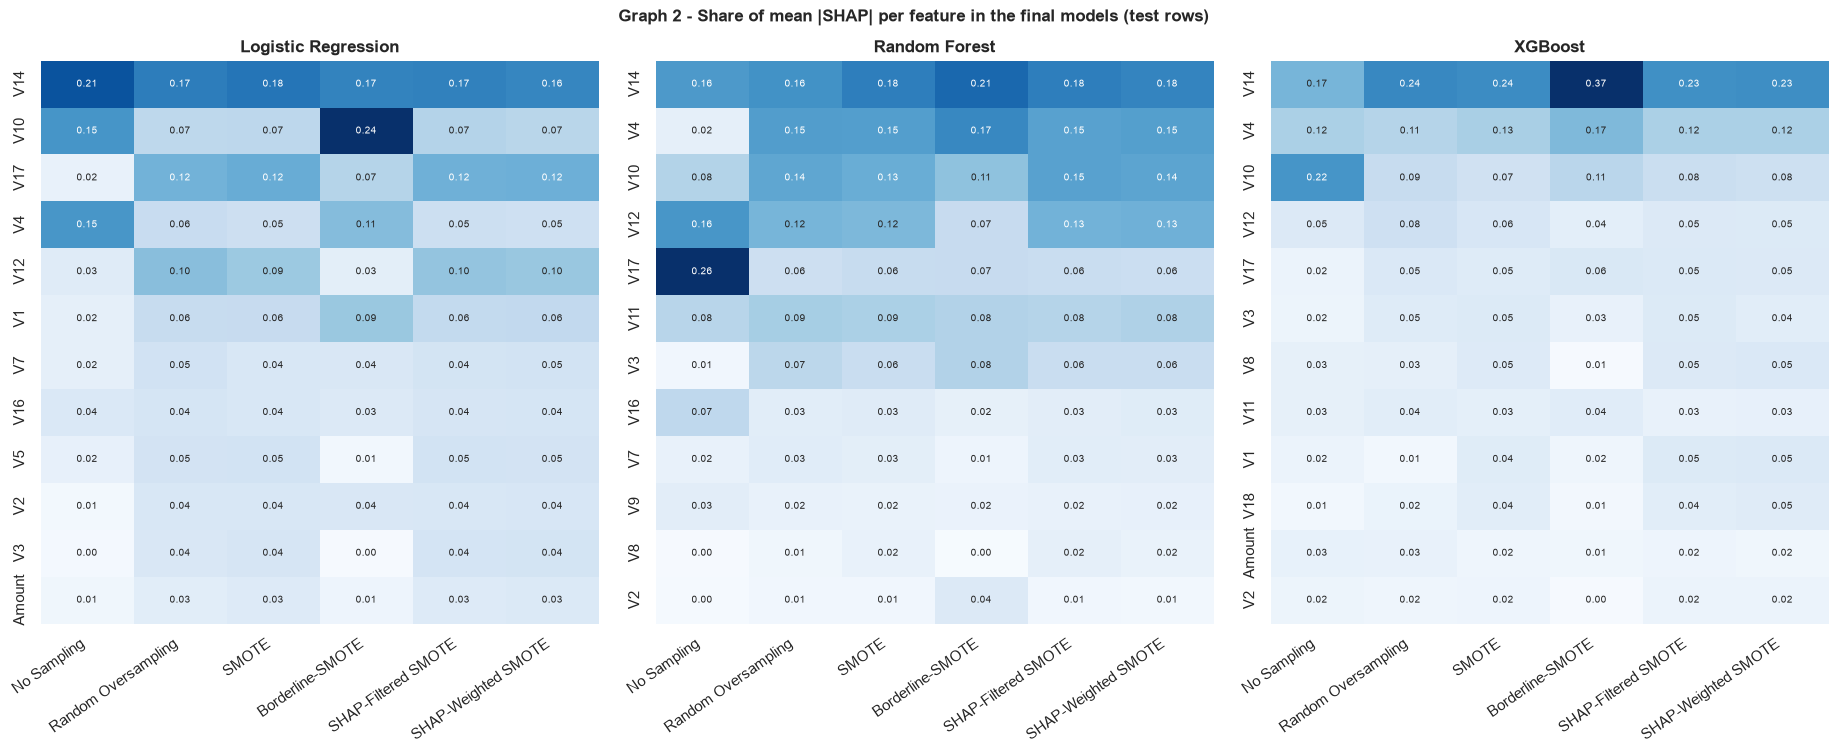

**Spearman correlation of each final model's feature-importance vector with the No Sampling model**

,Logistic Regression,Random Forest,XGBoost
No Sampling,1.0000,1.0000,1.0000
Random Oversampling,0.4562,0.7207,0.7552
SMOTE,0.4010,0.6961,0.5818
Borderline-SMOTE,0.5227,0.6507,0.6310
SHAP-Filtered SMOTE,0.4103,0.7039,0.6320
SHAP-Weighted SMOTE,0.4118,0.7192,0.5906


In [22]:
PL.shap_explainability_comparison(final, PLOTS); plt.show()
rank_corr = pd.DataFrame({model: final.importance_table(model).T.corr(method="spearman")["No Sampling"]
                          for model in C.MODEL_ORDER})
display(Markdown("**Spearman correlation of each final model's feature-importance vector with the No Sampling model**"))
display(rank_corr)

,,kendall_tau_mean,kendall_tau_std,spearman_rho_mean,spearman_rho_std,top_k_overlap
model,method,,,,,
Logistic Regression,No Sampling,0.6405,0.0871,0.7885,0.0870,0.7640
Random Forest,No Sampling,0.8495,0.0210,0.9543,0.0123,0.8000
XGBoost,No Sampling,0.6374,0.0606,0.7974,0.0583,0.8741
Logistic Regression,Random Oversampling,0.7413,0.0854,0.8839,0.0697,0.6794
Random Forest,Random Oversampling,0.8065,0.0520,0.9265,0.0367,0.9333
XGBoost,Random Oversampling,0.6668,0.0615,0.8228,0.0548,0.7556
Logistic Regression,SMOTE,0.7661,0.0921,0.8952,0.0697,0.6566
Random Forest,SMOTE,0.8033,0.0365,0.9250,0.0246,0.9333
XGBoost,SMOTE,0.7036,0.0754,0.8639,0.0644,0.5770


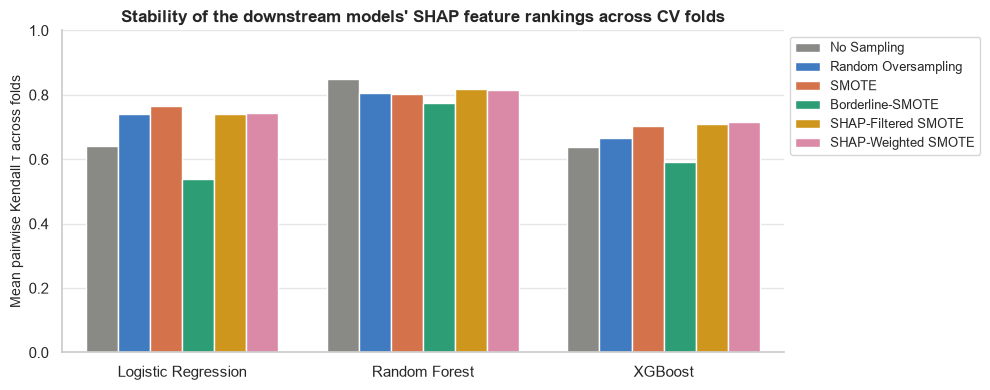

In [23]:
stability = R.attribution_stability(cv)
display(stability)
PL.attribution_stability_plot(stability, PLOTS); plt.show()

## Stage 8: Saved outputs and summary
Every table and figure is saved under `results/<dataset>/` (same layout for all datasets):
`metrics/`, `synthetic_samples/`, `neighbour_analysis/` and `plots/`.

In [24]:
saved = O.save_metrics(DIRS, dev_df, test_df, cv, final, stability, tests, quality_tbl)
display(saved)
print("plots:", ", ".join(sorted(p.name for p in PLOTS.glob("*.png"))))

,file
0,results/credit_card/metrics/split_assignment.c...
1,results/credit_card/metrics/cv_fold_metrics.csv
2,results/credit_card/metrics/cv_mean_metrics.csv
3,results/credit_card/metrics/cv_summary_mean_sd...
4,results/credit_card/metrics/cv_sampling_runtim...
5,results/credit_card/metrics/test_metrics.csv
6,results/credit_card/metrics/final_sampling_cou...
7,results/credit_card/metrics/attribution_stabil...
8,results/credit_card/metrics/paired_tests_vs_sm...
9,results/credit_card/metrics/synthetic_quality.csv


plots: 01_class_distribution.png, 02_feature_distributions.png, 03_correlation_heatmap.png, 04_class_comparison.png, 05_balanced_class_counts.png, 06_shap_feature_weights.png, 07_shap_summary_preliminary_model.png, 08_pca_original_vs_synthetic.png, 09_synthetic_feature_distributions.png, 10_graph1_performance_comparison.png, 11_cv_fold_stability.png, 12_roc_pr_curves.png, 13_confusion_matrices.png, 14_calibration_curves.png, 15_graph2_shap_explainability_comparison.png, 16_attribution_stability.png


### Final summary
Numbers below are computed from this run, not typed by hand.

In [25]:
display(Markdown(f"**Dataset:** {spec.title}, {len(df):,} rows, {len(spec.features)} raw features "
                 f"({len(pre.feature_names_)} model columns after encoding)."))
display(D.overview(df, spec))
display(Markdown("**Preprocessing:** stratified 75/25 development/test split; median / most-frequent imputation, "
                 "one-hot encoding and standard scaling fitted on training rows only; oversampling only inside "
                 "training folds."))
display(Markdown("**Oversampling results (final development-set fit):**"))
display(final.sampling.join(quality_tbl.reindex(columns=["majority_share_in_5nn", "mean_wasserstein_distance",
                                          "correlation_matrix_similarity", "detectability_auc_all", "detectability_auc_numeric"]), how="left"))
display(Markdown("**SHAP-guided vs SMOTE (CV mean difference, Wilcoxon p-value):**"))
display(S.dataset_findings(cv, tests, quality_tbl).T)
display(Markdown("**Findings derived from the numbers:**\n" + "\n".join(f"- {l}" for l in S.findings_text(cv, tests, quality_tbl))))

**Dataset:** Credit Card Fraud Detection (ULB), 275,663 rows, 29 raw features (29 model columns after encoding).

,Domain,Rows,Numeric features,Categorical features,Majority (0),Minority (1),Minority %,Imbalance ratio,Minority:majority
Dataset,,,,,,,,,
Credit Card Fraud Detection (ULB),Financial fraud,275663,29,0,275190,473,0.17%,581.8 : 1,1 : 581.8


**Preprocessing:** stratified 75/25 development/test split; median / most-frequent imputation, one-hot encoding and standard scaling fitted on training rows only; oversampling only inside training folds.

**Oversampling results (final development-set fit):**

,real_majority,real_minority,synthetic_minority,final_majority,final_minority,sampling_seconds,majority_share_in_5nn,mean_wasserstein_distance,correlation_matrix_similarity,detectability_auc_all,detectability_auc_numeric
method,,,,,,,,,,,
No Sampling,206392,355,0,206392,355,0.0551,NaN,NaN,NaN,NaN,NaN
Random Oversampling,206392,355,206037,206392,206392,1.8222,0.1976,0.0062,1.0000,NaN,NaN
SMOTE,206392,355,206037,206392,206392,5.9282,0.1772,0.1237,0.9971,0.5619,0.5619
Borderline-SMOTE,206392,355,206037,206392,206392,10.4167,0.3496,1.1780,0.9278,0.7844,0.7844
SHAP-Filtered SMOTE,206392,355,206037,206392,206392,30.9172,0.1756,0.1196,0.9970,0.5782,0.5782
SHAP-Weighted SMOTE,206392,355,206037,206392,206392,29.9306,0.1867,0.1199,0.9969,0.5755,0.5755


**SHAP-guided vs SMOTE (CV mean difference, Wilcoxon p-value):**

model,Logistic Regression,Random Forest,XGBoost
best PR-AUC,No Sampling (0.749),No Sampling (0.824),No Sampling (0.842)
best F1,No Sampling (0.724),No Sampling (0.831),No Sampling (0.862)
best recall,SHAP-Filtered SMOTE (0.911),SHAP-Weighted SMOTE (0.859),SMOTE (0.866)
SHAP-F - SMOTE PR-AUC,-0.005 (p=0.19),+0.020 (p=0.04),+0.003 (p=0.85)
SHAP-F - SMOTE F1,+0.001 (p=0.43),+0.029 (p=0.08),+0.025 (p=0.01)
SHAP-F - SMOTE Recall,+0.006 (p=0.12),+0.000 (p=1.00),-0.003 (p=0.69)
SHAP-F - SMOTE Precision,+0.001 (p=0.49),+0.027 (p=0.06),+0.022 (p=0.01)
SHAP-W - SMOTE PR-AUC,-0.003 (p=0.11),+0.024 (p=0.06),+0.006 (p=0.43)
SHAP-W - SMOTE F1,-0.001 (p=0.43),-0.004 (p=0.56),+0.025 (p=0.01)
SHAP-W - SMOTE Recall,+0.003 (p=0.62),+0.001 (p=1.00),-0.003 (p=0.88)


**Findings derived from the numbers:**
- Logistic Regression: PR-AUC ranking = No Sampling 0.749 > SMOTE 0.729 > SHAP-Weighted SMOTE 0.726 > Random Oversampling 0.725 > SHAP-Filtered SMOTE 0.724 > Borderline-SMOTE 0.704
-   SHAP-Filtered SMOTE vs SMOTE: PR-AUC -0.005 (4/10 folds better, p=0.193, not significant); F1 +0.001 (7/10 folds better, p=0.432, not significant); Recall +0.006 (4/4 folds better, p=0.125, not significant); Precision +0.001 (7/10 folds better, p=0.492, not significant)
-   SHAP-Weighted SMOTE vs SMOTE: PR-AUC -0.003 (3/10 folds better, p=0.105, not significant); F1 -0.001 (4/10 folds better, p=0.432, not significant); Recall +0.003 (3/4 folds better, p=0.625, not significant); Precision -0.000 (4/10 folds better, p=0.432, not significant)
- Random Forest: PR-AUC ranking = No Sampling 0.824 > Random Oversampling 0.762 > SHAP-Weighted SMOTE 0.760 > SHAP-Filtered SMOTE 0.756 > Borderline-SMOTE 0.737 > SMOTE 0.736
-   SHAP-Filtered SMOTE vs SMOTE: PR-AUC +0.020 (7/10 folds better, p=0.037, significant); F1 +0.029 (6/10 folds better, p=0.084, not significant); Recall +0.000 (4/6 folds better, p=1.000, not significant); Precision +0.027 (7/10 folds better, p=0.064, not significant)
-   SHAP-Weighted SMOTE vs SMOTE: PR-AUC +0.024 (7/10 folds better, p=0.064, not significant); F1 -0.004 (3/10 folds better, p=0.557, not significant); Recall +0.001 (3/4 folds better, p=1.000, not significant); Precision -0.004 (3/10 folds better, p=0.625, not significant)
- XGBoost: PR-AUC ranking = No Sampling 0.842 > Random Oversampling 0.826 > Borderline-SMOTE 0.817 > SHAP-Weighted SMOTE 0.814 > SHAP-Filtered SMOTE 0.811 > SMOTE 0.808
-   SHAP-Filtered SMOTE vs SMOTE: PR-AUC +0.003 (5/10 folds better, p=0.846, not significant); F1 +0.025 (8/10 folds better, p=0.010, significant); Recall -0.003 (2/6 folds better, p=0.688, not significant); Precision +0.022 (8/10 folds better, p=0.010, significant)
-   SHAP-Weighted SMOTE vs SMOTE: PR-AUC +0.006 (6/10 folds better, p=0.432, not significant); F1 +0.025 (9/10 folds better, p=0.014, significant); Recall -0.003 (3/6 folds better, p=0.875, not significant); Precision +0.021 (9/10 folds better, p=0.010, significant)
- Synthetic rows' majority share among 5 nearest real rows (lower = less overlap): Real minority (reference) 0.251, Random Oversampling 0.198, SMOTE 0.177, Borderline-SMOTE 0.350, SHAP-Filtered SMOTE 0.176, SHAP-Weighted SMOTE 0.187
- Mean marginal Wasserstein distance synthetic vs real minority (lower = closer): Random Oversampling 0.006, SMOTE 0.124, Borderline-SMOTE 1.178, SHAP-Filtered SMOTE 0.120, SHAP-Weighted SMOTE 0.120
- Correlation-structure similarity synthetic vs real minority (1 = identical): Random Oversampling 1.000, SMOTE 0.997, Borderline-SMOTE 0.928, SHAP-Filtered SMOTE 0.997, SHAP-Weighted SMOTE 0.997
- Real-vs-synthetic detectability AUC, all columns / numeric only (0.5 = indistinguishable): SMOTE 0.562 / 0.562, Borderline-SMOTE 0.784 / 0.784, SHAP-Filtered SMOTE 0.578 / 0.578, SHAP-Weighted SMOTE 0.575 / 0.575

### Interpretation: Credit Card Fraud (581.8 : 1)

**Which method performed best?** **No Sampling**, by a wide margin, on every metric except recall. XGBoost with no
sampling reaches CV F1 0.862 and PR-AUC 0.842; Random Forest reaches F1 0.831 and PR-AUC 0.824. Balancing 355
real frauds up to 206,392 rows (1:1) raises recall (XGBoost 0.80 → about 0.86, Random Forest 0.75 → about 0.86),
but it multiplies false alarms. Precision drops to 0.05–0.16 with Logistic Regression, 0.34–0.52 with Random Forest,
and 0.25–0.69 with XGBoost. Even the threshold-free PR-AUC is lower for every oversampler (best: Random Oversampling
with XGBoost, 0.826). Among the oversamplers, the best F1 is Borderline-SMOTE with XGBoost (0.747) and Random
Oversampling with Random Forest (0.643). Full 1:1 balancing is the wrong operating point at this imbalance.
That holds for every compared method, because they all share the same sampling target.

**Did SHAP-guided SMOTE improve minority-class detection?** Recall: no. It is the same as SMOTE (differences
≤ 0.006, none significant). Overall: yes, relative to SMOTE, through fewer false alarms at the same recall.
* **XGBoost:** F1 +0.025 for both SHAP methods (SHAP-Filtered better in 8/10 folds, p = 0.010; SHAP-Weighted 9/10,
  p = 0.014), precision +0.021–0.022 (p = 0.010 for both). These are the strongest positive results for the
  proposed methods in the whole benchmark.
* **Random Forest:** PR-AUC +0.020 (SHAP-Filtered, 7/10 folds, p = 0.037) and +0.024 (SHAP-Weighted, p = 0.065).
  SHAP-Filtered also improves F1 by +0.029 and precision by +0.027 (p = 0.08 and 0.06).
* **Logistic Regression:** no difference (all |Δ| ≤ 0.005).

**Did it improve or compromise precision?** It improved precision relative to SMOTE (by 8–9% relative with XGBoost
and 8% for SHAP-Filtered with Random Forest), but precision stays far below No Sampling. On the single hold-out
split (118 frauds) the XGBoost gain does not reproduce: SHAP-Filtered and SHAP-Weighted make 345 and 327 false
alarms against SMOTE's 315. The Random Forest gain does reproduce (SHAP-Filtered F1 0.525 vs 0.507).

**Did the synthetic samples preserve feature relationships?** Yes, for SMOTE and both SHAP methods. Correlation
similarity with the real frauds is 0.997, 97% of features pass the KS test, synthetic rows have fewer majority
neighbours than real frauds do (18% vs 25%), and they are hard to tell from real frauds (detectability AUC
0.56–0.58). SHAP guidance re-pairs about half of each fraud's neighbours (mean Jaccard 0.52–0.56 with SMOTE's).
SHAP-Filtered SMOTE searches on 13 of 29 features, led by V14, V17, V12 and V10, the components the earlier
credit-card notebook also identified as the fraud signal. Paired parents have slightly more similar explanations
(SHAP cosine 0.90–0.91 vs 0.90). Borderline-SMOTE fails every fidelity check (0% of features pass the KS
test, Wasserstein distance 10× SMOTE's, detectability 0.78).

**Where did SHAP-guided SMOTE fail or underperform?** It cannot fix the main problem on this dataset: any 1:1
oversampling of 355 frauds to 206,392 hurts more than it helps, so the best SHAP-guided result (XGBoost F1 0.417)
is less than half of No Sampling's (0.862). Its gains over SMOTE are real but second-order, and the
SHAP-Weighted F1 gain with Random Forest is slightly negative (−0.005). SHAP guidance also triples the oversampling
time (about 21 s vs 7 s per fold on 165,000-row training folds, even with the SHAP row cap).